# Projeto ML2 — Deteção de sopros cardíacos (CirCor DigiScope)

## 1. Introdução

**Objetivo.** Desenvolver classificadores de deep learning que detetem sopros cardíacos a partir de gravações de auscultação (fonocardiogramas). Para cada paciente, o sistema produz uma única previsão: Present (há sopro), Absent (não há sopro) ou Unknown (o especialista não conseguiu decidir, por exemplo por ruído ou má qualidade da gravação).

**Dados.** Parte pública do dataset CirCor DigiScope: 3163 gravações de 942 pacientes, com até quatro localizações de auscultação por paciente (válvulas aórtica, pulmonar, tricúspide e mitral) e durações entre cerca de 5 s e 65 s. Das labels disponíveis usa-se apenas a label Murmur como alvo. O campo `Murmur locations` é usado unicamente para preparar as labels de treino por gravação (secção 3.2); nunca é usado como input nem na avaliação.

**Modelos.** Dois dos três classificadores permitidos:
- uma CNN 2D, que recebe o espectrograma mel de cada janela de som;
- uma RNN (GRU), que recebe a sequência de MFCCs de cada janela.

**Avaliação.** Tal como pede o enunciado, a métrica principal é a weighted accuracy da tarefa de sopros do PhysioNet Challenge 2022 (WAmurmur), calculada por paciente, acompanhada da matriz de confusão por paciente. As decisões são tomadas apenas com o conjunto de validação; o conjunto de teste é usado uma única vez, no fim.

**Estrutura do notebook.**
- Secção 3: análise exploratória.
- Secção 4: pré-processamento (divisão dos dados, limpeza do sinal, janelas e features).
- Secção 5: CNN e respetivas experiências.
- Secção 6: RNN e respetivas experiências.
- Secção 7: ensemble, classe Unknown e avaliação final no teste.
- Secção 8: resumo das experiências e conclusões.

**Como executar.**
1. Ambiente Python 3.11 com `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `librosa`, `soundfile`, `torch`, `tqdm` e `jupyter`.
2. O dataset deve estar na pasta `circor/`, ao lado do notebook: `circor/training_data.csv` e `circor/training_data/` (ficheiros `.wav` e `.tsv`).
3. Correr todas as células por ordem (Restart + Run All). Na primeira execução são criados ficheiros de cache (`signals.pkl`, `mel.npy`, `mfcc.npy`, cerca de 2,5 GB no total), reutilizados nas execuções seguintes. Se o pré-processamento ou as features forem alterados, estes ficheiros têm de ser apagados.
4. Em CPU, a execução completa demora cerca de 3 horas, quase todas gastas nos treinos. As sementes aleatórias estão fixas, pelo que os resultados são reprodutíveis na mesma máquina.

## 2. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

DATA_DIR = "circor"
CSV_PATH = os.path.join(DATA_DIR, "training_data.csv")
WAV_DIR = os.path.join(DATA_DIR, "training_data")


WINDOW_SEC = 5      # duração de cada janela, em segundos
SR = 4000           # frequência de amostragem das gravações (Hz)

Device: cpu


## 3. Análise exploratória

### 3.1 Labels por paciente

Carregamento do ficheiro `training_data.csv`, que tem uma linha por paciente, e inspeção das suas dimensões e colunas.

In [2]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(942, 23)


,Patient ID,Recording locations:,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Systolic murmur pitch,Systolic murmur quality,Diastolic murmur timing,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Outcome,Campaign,Additional ID
0,2530,AV+PV+TV+MV,Child,Female,98.0,15.9,False,Absent,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
1,9979,AV+PV+TV+MV,Child,Female,103.0,13.1,False,Present,AV+MV+PV+TV,TV,...,High,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
2,9983,AV+PV+TV+MV,Child,Male,115.0,19.1,False,Unknown,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
3,13918,AV+PV+TV+MV,Child,Male,98.0,15.9,False,Present,TV,TV,...,Low,Blowing,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
4,14241,AV+PV+TV+MV,Child,Male,87.0,11.2,False,Present,AV+MV+PV+TV,PV,...,Low,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN


Lista das colunas disponíveis no ficheiro.

In [3]:
df.columns.tolist()

['Patient ID',
 'Recording locations:',
 'Age',
 'Sex',
 'Height',
 'Weight',
 'Pregnancy status',
 'Murmur',
 'Murmur locations',
 'Most audible location',
 'Systolic murmur timing',
 'Systolic murmur shape',
 'Systolic murmur grading',
 'Systolic murmur pitch',
 'Systolic murmur quality',
 'Diastolic murmur timing',
 'Diastolic murmur shape',
 'Diastolic murmur grading',
 'Diastolic murmur pitch',
 'Diastolic murmur quality',
 'Outcome',
 'Campaign',
 'Additional ID']

Seleção das colunas necessárias: o identificador do paciente, a label Murmur e as colunas sobre a localização dos sopros e das gravações.

In [4]:
cols = ["Patient ID", "Murmur", "Murmur locations", "Recording locations:", "Most audible location"]
labels = df[cols].copy()
labels.head()

,Patient ID,Murmur,Murmur locations,Recording locations:,Most audible location
0,2530,Absent,NaN,AV+PV+TV+MV,NaN
1,9979,Present,AV+MV+PV+TV,AV+PV+TV+MV,TV
2,9983,Unknown,NaN,AV+PV+TV+MV,NaN
3,13918,Present,TV,AV+PV+TV+MV,TV
4,14241,Present,AV+MV+PV+TV,AV+PV+TV+MV,PV


Número e proporção de pacientes em cada classe.

In [5]:
print(labels["Murmur"].value_counts())
print(labels["Murmur"].value_counts(normalize=True).round(3))

Murmur
Absent     695
Present    179
Unknown     68
Name: count, dtype: int64
Murmur
Absent     0.738
Present    0.190
Unknown    0.072
Name: proportion, dtype: float64


### Distribuição das classes (Murmur)

O dataset público tem **942 pacientes**, distribuídos da seguinte forma:

| Classe  | Pacientes | %      |
|---------|----------:|-------:|
| Absent  | 695       | 73,8 % |
| Present | 179       | 19,0 % |
| Unknown | 68        | 7,2 %  |

**Observações:**

1. **Forte desequilíbrio entre classes.** Um modelo que previsse sempre "Absent" teria uma accuracy de **73,8 %** sem detetar nenhum sopro. Por isso, a accuracy **não é uma métrica adequada** para avaliar os modelos.

2. **Métricas a usar:**
   - **WAmurmur**, a métrica principal definida no enunciado, em que acertar um Present vale 5, um Unknown 3 e um Absent 1 (apresentada na secção 5.4);
   - **Matriz de confusão por paciente**, para ver onde cada classe é confundida;
   - como métricas adicionais, o **recall por classe** e o **F1 macro**.

3. **Contexto clínico:** falhar um Present (falso negativo) é mais grave do que um falso alarme, que apenas leva a exames adicionais. O recall da classe Present é, por isso, prioritário.

4. **Implicações para o treino:** será necessário compensar o desequilíbrio, por exemplo com class weights na função de perda, oversampling ou data augmentation das classes minoritárias.

5. **A classe Unknown é a mais difícil:** tem poucos exemplos (68) e corresponde a casos em que o próprio especialista não conseguiu decidir. Esperam-se resultados mais fracos nesta classe.

### 3.2 Tabela de gravações

Cada paciente tem várias gravações (uma por válvula, por vezes repetidas), mas a label Murmur é atribuída ao paciente. Para treinar os modelos é preciso uma tabela com **uma linha por gravação**, construída a partir dos nomes dos ficheiros `.wav` (formato `IDPACIENTE_VÁLVULA[_n].wav`) e associada às labels do paciente.

In [6]:
#Quantos ficheiros .wav tem o dataset

import glob
wav_files = sorted(glob.glob(os.path.join(WAV_DIR, "*.wav")))
len(wav_files)

3163

In [7]:
#Para cada ficheiro, extrair o ID e a válvula

nome = os.path.basename(wav_files[0])   # tira a pasta, fica só "1234_AV.wav"
partes = nome.replace(".wav", "").split("_")
partes

['13918', 'AV']

Construção da tabela de gravações: de cada nome de ficheiro extraem-se o identificador do paciente e a válvula.

In [8]:
linhas = []

for path in wav_files:
    nome = os.path.basename(path)
    partes = nome.replace(".wav", "").split("_")

    patient_id = int(partes[0])
    location = partes[1]

    linhas.append({
        "path": path,
        "patient_id": patient_id,
        "location": location,
    })

rec = pd.DataFrame(linhas)
print(rec.shape)
rec.head()

(3163, 3)


,path,patient_id,location
0,circor/training_data/13918_AV.wav,13918,AV
1,circor/training_data/13918_MV.wav,13918,MV
2,circor/training_data/13918_PV.wav,13918,PV
3,circor/training_data/13918_TV.wav,13918,TV
4,circor/training_data/14241_AV.wav,14241,AV


Associação das labels do paciente a cada gravação.

In [9]:
rec = rec.merge(labels, left_on="patient_id", right_on="Patient ID")
print(rec.shape)
rec.head()

(3163, 8)


,path,patient_id,location,Patient ID,Murmur,Murmur locations,Recording locations:,Most audible location
0,circor/training_data/13918_AV.wav,13918,AV,13918,Present,TV,AV+PV+TV+MV,TV
1,circor/training_data/13918_MV.wav,13918,MV,13918,Present,TV,AV+PV+TV+MV,TV
2,circor/training_data/13918_PV.wav,13918,PV,13918,Present,TV,AV+PV+TV+MV,TV
3,circor/training_data/13918_TV.wav,13918,TV,13918,Present,TV,AV+PV+TV+MV,TV
4,circor/training_data/14241_AV.wav,14241,AV,14241,Present,AV+MV+PV+TV,AV+PV+TV+MV,PV


Duas colunas auxiliares por gravação: `most_audible` (é a localização onde o sopro se ouve melhor?) e `murmur_here` (o sopro foi ouvido nesta válvula?).

In [10]:
rec["most_audible"] = rec["location"] == rec["Most audible location"]

def murmur_here(row):
    if pd.isna(row["Murmur locations"]):
        return False
    lista = row["Murmur locations"].split("+")
    return row["location"] in lista

rec["murmur_here"] = rec.apply(murmur_here, axis=1)

Verificação com um paciente Present cujo sopro só foi ouvido na válvula tricúspide (TV).

In [11]:
rec[rec["patient_id"] == 13918][["location", "Murmur", "Murmur locations", "murmur_here", "most_audible"]]

,location,Murmur,Murmur locations,murmur_here,most_audible
0,AV,Present,TV,False,False
1,MV,Present,TV,False,False
2,PV,Present,TV,False,False
3,TV,Present,TV,True,True


Número de gravações de cada classe em que o sopro foi, ou não, ouvido na respetiva válvula.

In [12]:
pd.crosstab(rec["Murmur"], rec["murmur_here"])

murmur_here,False,True
Murmur,,
Absent,2391,0
Present,117,499
Unknown,156,0


**Decisão — label por gravação (`label_rec`):** as 117 gravações de pacientes Present em que o sopro não foi ouvido (válvula fora de `Murmur locations`) passam a Absent para efeitos de treino. Sem esta correção, o modelo seria treinado a chamar Present a sons em que o especialista não ouviu sopro. A coluna `Murmur` original mantém-se para a avaliação, que é feita por paciente. O campo `Murmur locations` serve apenas para construir estas labels de treino: não é input dos modelos nem é necessário para prever pacientes novos.

In [13]:
def label_rec(row):
    if row["Murmur"] == "Present" and not row["murmur_here"]:
        return "Absent"
    return row["Murmur"]

rec["label_rec"] = rec.apply(label_rec, axis=1)
rec["label_rec"].value_counts()

label_rec
Absent     2508
Present     499
Unknown     156
Name: count, dtype: int64

#### Gravações por paciente e por válvula

Como a label é atribuída ao paciente e o treino é feito por gravação, importa saber quantas gravações tem cada paciente: pacientes com mais gravações têm mais peso no treino. Verifica-se também a distribuição por válvula e o número de gravações repetidas da mesma válvula.

In [14]:
print("Nº de gravações por paciente:")
print(rec.groupby("patient_id").size().value_counts().sort_index())

print("\nNº de gravações por válvula:")
print(rec["location"].value_counts())

n_rep = rec.duplicated(subset=["patient_id", "location"], keep=False).sum()
print("\nGravações que repetem a válvula do mesmo paciente:", n_rep)

Nº de gravações por paciente:
1     62
2    156
3    123
4    588
5     10
6      3
Name: count, dtype: int64

Nº de gravações por válvula:
location
MV     861
AV     800
PV     766
TV     732
Phc      4
Name: count, dtype: int64

Gravações que repetem a válvula do mesmo paciente: 43


**Observações:**
- A maioria dos pacientes (588 de 942, 62 %) tem 4 gravações, uma por válvula. 341 pacientes (36 %) têm menos de 4 gravações e apenas 13 têm mais (5 ou 6), devido a gravações repetidas.
- As quatro válvulas principais estão representadas de forma equilibrada: MV (861), AV (800), PV (766) e TV (732). A localização Phc (outra localização) é muito rara, com apenas 4 gravações.
- Existem 43 gravações que repetem a válvula do mesmo paciente (ficheiros `_1`, `_2`). São tratadas como gravações independentes, mas ficam sempre no mesmo conjunto (treino, validação ou teste), porque o split é feito por paciente.
- Os 62 pacientes com uma única gravação são um caso particular na avaliação por paciente: se o sopro estiver numa válvula que não foi gravada, nenhum modelo o consegue detetar a partir dos dados disponíveis. Este ponto será retomado na discussão dos resultados.

### 3.3 Duração das gravações

In [15]:
import soundfile as sf

info = sf.info(rec["path"].iloc[0])
print(info)

circor/training_data/13918_AV.wav
samplerate: 4000 Hz
channels: 1
duration: 10.288 s
format: WAV (Microsoft) [WAV]
subtype: Signed 16 bit PCM [PCM_16]


Duração de cada gravação, lida do cabeçalho do ficheiro sem carregar o áudio.

In [16]:
rec["duration"] = rec["path"].apply(lambda p: sf.info(p).duration)

rec[["path", "label_rec", "duration"]].head()

,path,label_rec,duration
0,circor/training_data/13918_AV.wav,Absent,10.288
1,circor/training_data/13918_MV.wav,Absent,28.784
2,circor/training_data/13918_PV.wav,Absent,9.392
3,circor/training_data/13918_TV.wav,Present,6.592
4,circor/training_data/14241_AV.wav,Present,20.480


Estatísticas descritivas da duração.

In [17]:
rec["duration"].describe()

count    3163.000000
mean       22.870301
std         7.282948
min         5.152000
25%        19.056000
50%        21.456000
75%        29.392000
max        64.512000
Name: duration, dtype: float64

Histograma da duração.

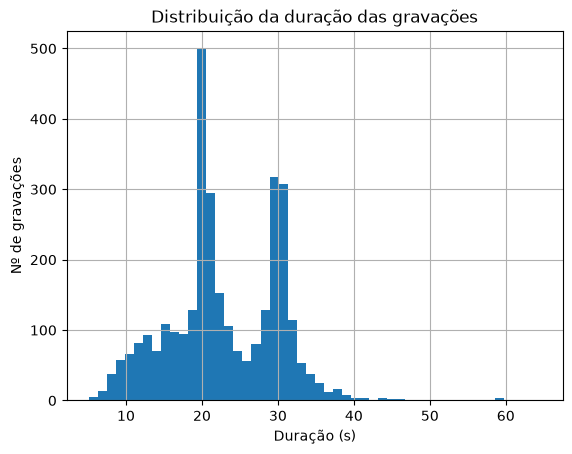

In [18]:
rec["duration"].hist(bins=50)
plt.xlabel("Duração (s)")
plt.ylabel("Nº de gravações")
plt.title("Distribuição da duração das gravações")
plt.show()

Duração por classe.

In [19]:
rec.groupby("label_rec")["duration"].describe()

,count,mean,std,min,25%,50%,75%,max
label_rec,,,,,,,,
Absent,2508.0,22.924904,7.129434,5.152,19.056,21.552,29.464,58.752
Present,499.0,22.741355,8.097988,6.384,18.920,21.248,28.944,64.512
Unknown,156.0,22.404923,6.993879,7.552,19.172,21.072,27.208,43.888


**Observações sobre a duração:**
- As durações variam entre 5,2 s e 64,5 s (mediana 21,5 s), com dois picos claros à volta dos 20 s e dos 30 s, o que sugere durações-padrão no protocolo de gravação.
- A distribuição da duração é praticamente igual nas três classes, por isso a duração não é um indicador da classe.
- Como os modelos exigem inputs de tamanho fixo, as gravações serão divididas em janelas. Com uma duração mínima de ~5 s, uma janela de 4 a 5 s cabe em todas as gravações e contém vários ciclos cardíacos completos.

### 3.4 Visualização dos sons

Escolha de um exemplo Present (na localização onde o sopro é mais audível) e de um exemplo Absent.

In [20]:
ex_present = rec[(rec["label_rec"] == "Present") & (rec["most_audible"])].iloc[0]
ex_absent = rec[rec["label_rec"] == "Absent"].iloc[0]

Função que desenha a waveform e o espectrograma mel dos primeiros 5 s de uma gravação, aplicada aos dois exemplos.

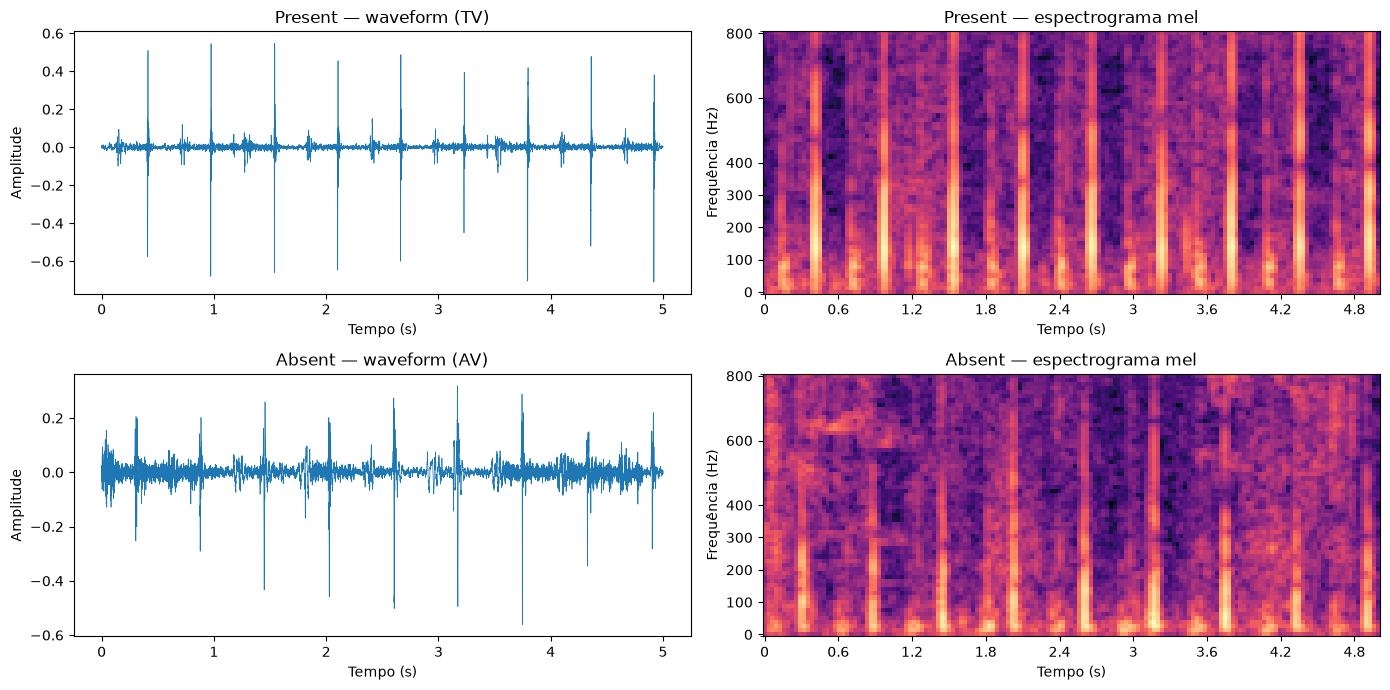

In [21]:
import librosa
import librosa.display

def plot_example(row, axes, titulo):
    # 1. carregar só os primeiros WINDOW_SEC segundos
    y, sr = librosa.load(row["path"], sr=None, duration=WINDOW_SEC)

    # 2. waveform (esquerda)
    t = np.arange(len(y)) / sr
    axes[0].plot(t, y, linewidth=0.5)
    axes[0].set_title(f"{titulo} — waveform ({row['location']})")
    axes[0].set_xlabel("Tempo (s)")
    axes[0].set_ylabel("Amplitude")

    # 3. espectrograma mel (direita)
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=512, hop_length=128, n_mels=64, fmax=800)
    S_db = librosa.power_to_db(S, ref=np.max)
    librosa.display.specshow(S_db, sr=sr, hop_length=128, x_axis="time", y_axis="mel", fmax=800, ax=axes[1])
    axes[1].set_yticks([0, 100, 200, 300, 400, 600, 800])
    axes[1].set_ylabel("Frequência (Hz)")
    axes[1].set_xlabel("Tempo (s)")
    axes[1].set_title(f"{titulo} — espectrograma mel")

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_example(ex_present, axes[0], "Present")
plot_example(ex_absent, axes[1], "Absent")
plt.tight_layout()
plt.show()

**Espectrograma mel**

O espectrograma representa a energia do som em cada frequência ao longo do tempo: o eixo x é o tempo, o eixo y a frequência e a cor a energia. É obtido dividindo o sinal em janelas curtas (512 amostras ≈ 0,13 s, com avanço de 128 amostras) e calculando o espectro de cada uma.

Na escala mel, as frequências são agrupadas em bandas (64, até 800 Hz) com maior resolução nas frequências baixas, imitando a perceção auditiva humana. Isto é adequado a sons cardíacos, cuja informação relevante está abaixo de ~500 Hz (S1 e S2 abaixo de ~150 Hz; sopros até ~500 Hz). A energia é convertida para decibéis, para que componentes mais fracas, como os sopros, não fiquem escondidas pelos S1 e S2.

O espectrograma mel transforma o som numa imagem 2D, o que o torna um input natural para uma CNN.

**Observações dos exemplos:**
- Os S1 e S2 aparecem como riscas verticais curtas e intensas, repetidas a cada batimento.
- O exemplo Absent tem mais ruído de fundo do que o exemplo Present, o que mostra que "som pouco limpo" não implica a presença de sopro.
- As amplitudes variam muito entre gravações, o que justifica normalizar cada gravação no pré-processamento.

Para ilustrar claramente o padrão de um sopro, compara-se ainda um caso de sopro forte (grau III/VI, holossistólico), na localização onde é mais audível, com os dois exemplos anteriores.

In [22]:
fortes = df[(df["Systolic murmur grading"] == "III/VI") & (df["Systolic murmur timing"] == "Holosystolic")]
print(len(fortes))
fortes[["Patient ID", "Most audible location"]].head()

33


,Patient ID,Most audible location
1,9979,TV
21,44514,PV
33,49574,TV
43,49628,TV
68,49821,MV


Escolha de um desses pacientes e da gravação onde o sopro é mais audível.

In [23]:
pid = fortes["Patient ID"].iloc[0]
ex_forte = rec[(rec["patient_id"] == pid) & (rec["most_audible"])].iloc[0]

Comparação dos três exemplos: sopro forte, Present e Absent.

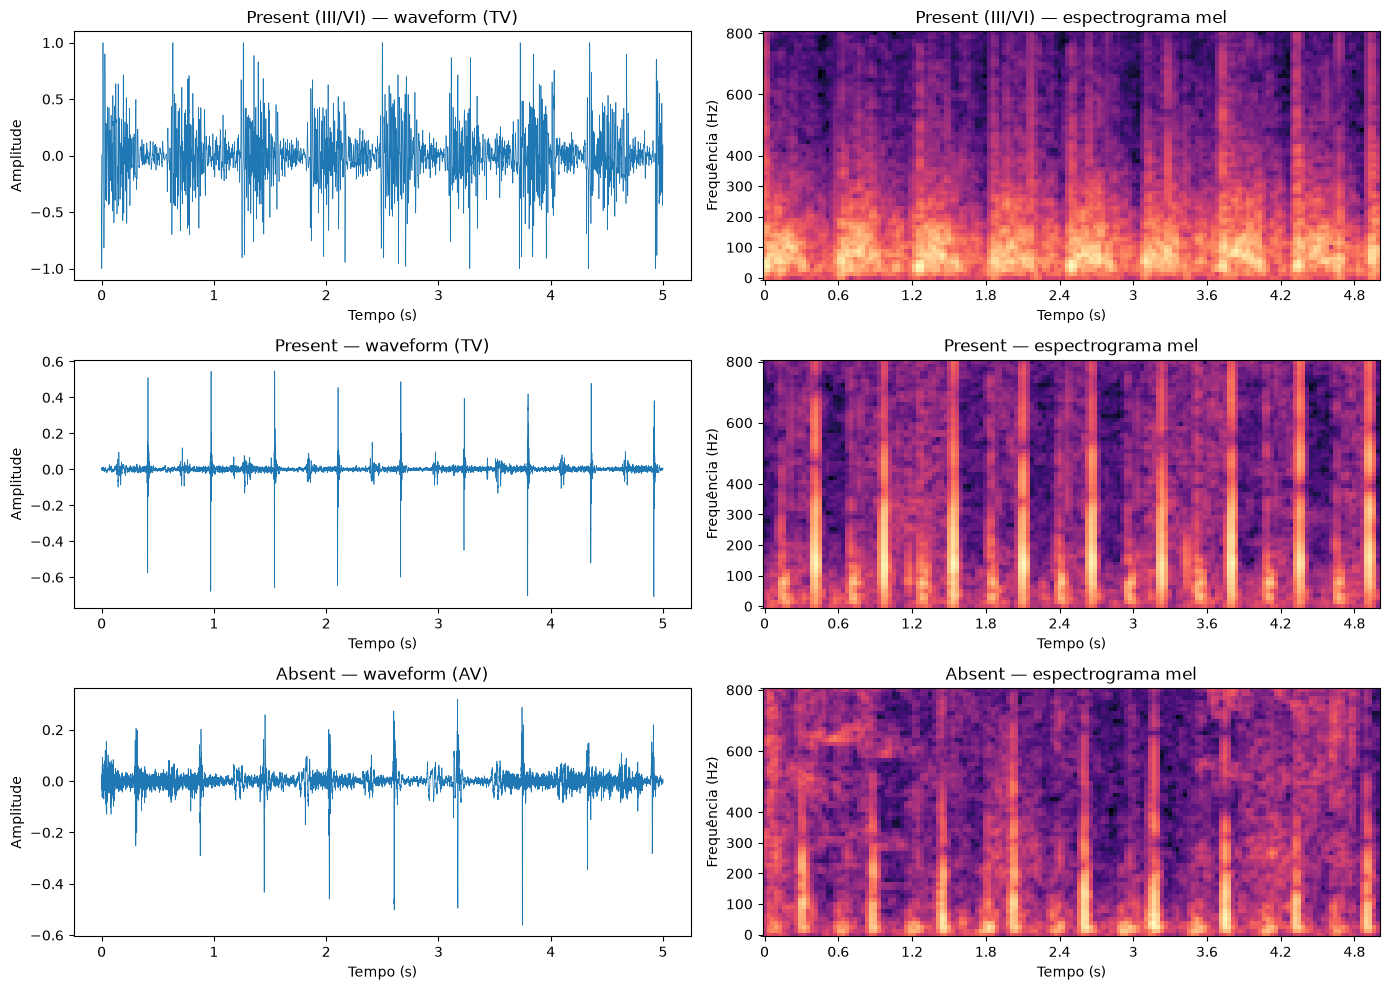

In [24]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
plot_example(ex_forte, axes[0], "Present (III/VI)")
plot_example(ex_present, axes[1], "Present")
plot_example(ex_absent, axes[2], "Absent")
plt.tight_layout()
plt.show()

**Observações:**
- No caso de sopro forte (III/VI, holossistólico), o sopro aparece como blocos de energia contínua entre ~0 e 300 Hz que preenchem o intervalo entre batimentos e se repetem em todos os ciclos. Ao contrário do ruído do exemplo Absent, que está espalhado e sem ritmo, o sopro está concentrado nas frequências baixas e sincronizado com o ciclo cardíaco.
- A energia do sopro concentra-se abaixo de ~400 Hz, o que justifica um filtro passa-baixo nessa zona e o limite de 800 Hz no espectrograma mel.

#### Sobreposição da segmentação do ciclo cardíaco

Cada gravação tem um ficheiro `.tsv` com a segmentação do ciclo cardíaco, feita por algoritmos e validada por especialistas. Cada linha indica o início e o fim (em segundos) de uma fase:

| Código | Fase |
|---|---|
| 1 | S1 (fecho das válvulas mitral e tricúspide, início da sístole) |
| 2 | Sístole (contração do coração) |
| 3 | S2 (fecho das válvulas aórtica e pulmonar, início da diástole) |
| 4 | Diástole (relaxamento do coração) |
| 0 | Sem anotação |

**Porquê sobrepor a segmentação?**

Um sopro distingue-se do ruído por estar sincronizado com o ciclo cardíaco: aparece sempre na mesma fase (por exemplo, na sístole) e repete-se em todos os batimentos. Ao marcar as fases sobre os gráficos é possível verificar se a energia observada no caso de sopro forte cai, de facto, na sístole, e confirmar que os S1 e S2 correspondem às riscas verticais do espectrograma.

Esta verificação ajuda a validar a interpretação dos espectrogramas e mostra que a informação temporal (em que fase do ciclo surge a energia) é relevante. Isto favorece modelos que preservam a estrutura temporal do sinal, como a CNN sobre espectrogramas ou a RNN.

In [25]:
def load_segments(row):
    tsv_path = row["path"].replace(".wav", ".tsv")
    seg = pd.read_csv(tsv_path, sep="\t", header=None, names=["start", "end", "state"])
    return seg[seg["start"] < WINDOW_SEC]    # só as fases dentro da janela de 5 s

load_segments(ex_forte).head(10)

,start,end,state
0,0.000000,0.540500,0
1,0.540500,0.700435,1
2,0.700435,0.860337,2
3,0.860337,0.963066,3
4,0.963066,1.173507,4
5,1.173507,1.420337,1
6,1.420337,1.500337,2
7,1.500337,1.620337,3
8,1.620337,1.789679,4
9,1.789679,2.020337,1


Função que pinta a sístole (vermelho) e a diástole (azul) sobre um gráfico.

In [26]:
CORES = {2: ("tab:red", "Sístole"), 4: ("tab:blue", "Diástole")}

def add_segments(ax, row):
    seg = load_segments(row)
    for _, s in seg.iterrows():
        if s["state"] in CORES:
            cor, _ = CORES[s["state"]]
            ax.axvspan(s["start"], min(s["end"], WINDOW_SEC), color=cor, alpha=0.2)

Exemplo de sopro forte com as fases do ciclo sobrepostas.

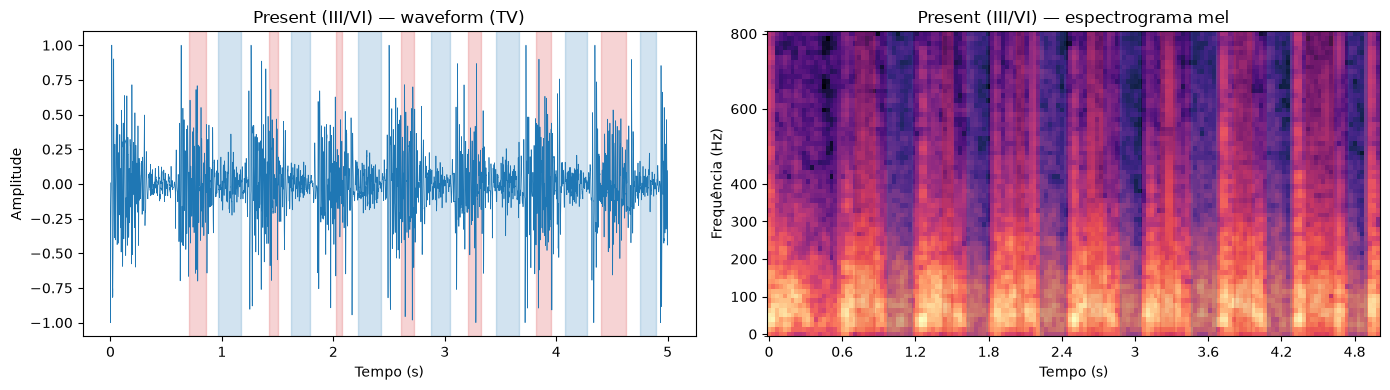

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_example(ex_forte, axes, "Present (III/VI)")
add_segments(axes[0], ex_forte)
add_segments(axes[1], ex_forte)
plt.tight_layout()
plt.show()

**Observação:** a energia do sopro concentra-se na sístole (faixas vermelhas) e nos S1 que a antecedem, repetindo-se em todos os ciclos, enquanto a diástole (faixas azuis) é praticamente silenciosa. Isto confirma que o sopro deste paciente é sistólico, de acordo com a anotação clínica (holossistólico), e que o que distingue um sopro do ruído é a sua sincronização com o ciclo cardíaco. Nota-se ainda que o início da gravação (~0,7 s) não tem segmentação (código 0), embora contenha o mesmo padrão.

### 3.5 Resumo da análise exploratória

**Dados**
- O dataset público tem 942 pacientes e 3163 gravações, amostradas a 4000 Hz.
- A label Murmur é atribuída ao paciente: Absent (73,8 %), Present (19,0 %) e Unknown (7,2 %).

**Desequilíbrio entre classes**
- Um modelo que previsse sempre Absent teria 73,8 % de accuracy sem detetar nenhum sopro. A avaliação é feita com a WAmurmur e a matriz de confusão por paciente, com o recall por classe e o F1 macro como métricas adicionais.
- Será necessário compensar o desequilíbrio no treino (class weights, oversampling ou data augmentation).

**Label por gravação**
- 117 das 616 gravações de pacientes Present (19 %) foram feitas em válvulas onde o sopro não foi ouvido. Para o treino, estas gravações passam a Absent (coluna `label_rec`). A avaliação final é feita por paciente, com a label original.
- Ao nível das gravações, o desequilíbrio aumenta: 2508 Absent, 499 Present e 156 Unknown.

**Duração**
- As gravações variam entre 5,2 s e 64,5 s (mediana 21,5 s), com dois picos à volta dos 20 s e dos 30 s. A duração é semelhante nas três classes, por isso não é indicadora da classe.
- Os modelos exigem inputs de tamanho fixo: as gravações serão divididas em janelas de 5 s, que cabem em todas as gravações e contêm vários ciclos cardíacos.

**Características do sinal**
- Os S1 e S2 aparecem como eventos curtos e intensos; um sopro aparece como energia contínua, concentrada abaixo de ~400 Hz e sincronizada com o ciclo cardíaco (no exemplo analisado, na sístole).
- Muitas gravações têm ruído de fundo (fala, choro, fricção), que pode confundir-se com um sopro. O que distingue os dois é a sincronização com o ciclo cardíaco, o que favorece modelos que preservam a estrutura temporal.
- As amplitudes variam muito entre gravações (incluindo possível saturação), independentemente da classe.

**Decisões para o pré-processamento**
1. Divisão treino / validação / teste por paciente, para evitar data leakage.
2. Filtro passa-banda (~25–400 Hz) para remover ruído fora da banda útil.
3. Normalização da amplitude de cada gravação.
4. Divisão em janelas de 5 s.
5. Espectrograma mel (até 800 Hz) como representação de input para a CNN.

## 4. Pré-processamento
### 4.1 Divisão treino / validação / teste

Os dados são divididos em treino (70 %), validação (15 %) e teste (15 %):
- **Treino:** usado para ajustar os pesos dos modelos.
- **Validação:** usado para tomar decisões durante o desenvolvimento (escolha de hiperparâmetros, pré-processamento e arquitetura, deteção de overfitting e early stopping). Nunca é usado para ajustar os pesos.
- **Teste:** usado apenas uma vez, na avaliação final, para obter uma estimativa não enviesada do desempenho.

A divisão é feita **por paciente**, para que todas as gravações do mesmo paciente fiquem no mesmo conjunto e o modelo nunca seja avaliado em pacientes que viu durante o treino (evitando data leakage). É também estratificada pela label Murmur, para manter a proporção das três classes em cada conjunto, o que é importante sobretudo para a classe Unknown, que tem poucos pacientes.

**Crianças com dois registos.** Algumas crianças participaram nas duas campanhas de rastreio e têm dois identificadores no dataset (coluna `Additional ID`): 70 crianças, 140 dos 942 registos. Para evitar que a mesma criança apareça em conjuntos diferentes, a divisão é feita por criança e não por identificador: os dois registos recebem um identificador comum (`subject`) e ficam sempre no mesmo conjunto. A célula de verificação confirma que nenhum dos 140 pares fica repartido.

In [28]:
from sklearn.model_selection import train_test_split

SEED = 42

# 1. Número único por criança: os dois IDs da mesma criança ficam com o mesmo "subject"
subject = {pid: pid for pid in labels["Patient ID"]}
for pid, add in zip(df["Patient ID"], df["Additional ID"]):
    if pd.notna(add) and int(add) in subject:
        m = min(subject[pid], subject[int(add)])
        subject[pid] = subject[int(add)] = m
labels["subject"] = labels["Patient ID"].map(subject)

# 2. Uma linha por criança, para dividir crianças e não registos
subj = labels.drop_duplicates("subject")[["subject", "Murmur"]]

# 3. 1ª divisão: 70 % treino, 30 % resto
train_s, rest_s = train_test_split(
    subj["subject"], test_size=0.30, stratify=subj["Murmur"], random_state=SEED)

# 4. 2ª divisão: o resto ao meio → 15 % validação, 15 % teste
rest_labels = subj.set_index("subject").loc[rest_s, "Murmur"]
val_s, test_s = train_test_split(
    rest_s, test_size=0.50, stratify=rest_labels, random_state=SEED)

# 5. Voltar aos IDs dos pacientes (o resto do notebook usa estas três variáveis)
train_ids = labels.loc[labels["subject"].isin(train_s), "Patient ID"]
val_ids = labels.loc[labels["subject"].isin(val_s), "Patient ID"]
test_ids = labels.loc[labels["subject"].isin(test_s), "Patient ID"]

print(labels["subject"].nunique(), "crianças;", len(train_ids), len(val_ids), len(test_ids), "registos")

872 crianças; 659 138 145 registos


Atribuição de cada gravação ao conjunto do seu paciente.

In [29]:
def get_split(pid):
    if pid in set_train:
        return "train"
    if pid in set_val:
        return "val"
    return "test"

set_train, set_val = set(train_ids), set(val_ids)
rec["split"] = rec["patient_id"].apply(get_split)

Verificações: nenhum paciente em dois conjuntos, proporção das classes por conjunto e número de gravações por conjunto e classe.

In [30]:
# Nenhum paciente pode estar em dois conjuntos
assert not (set(train_ids) & set(val_ids))
assert not (set(train_ids) & set(test_ids))
assert not (set(val_ids) & set(test_ids))

# Proporção das classes por conjunto (por paciente)
pac = rec.drop_duplicates("patient_id")
print(pd.crosstab(pac["split"], pac["Murmur"], normalize="index").round(3))

# Nº de gravações por conjunto e classe (label usada no treino)
print(pd.crosstab(rec["split"], rec["label_rec"]))

Murmur  Absent  Present  Unknown
split                           
test     0.717    0.200    0.083
train    0.741    0.190    0.070
val      0.746    0.181    0.072
label_rec  Absent  Present  Unknown
split                              
test          378       86       33
train        1771      342      102
val           359       71       21


Verificação de que os dois registos de cada criança ficaram no mesmo conjunto.

In [31]:
extra = df.loc[df["Additional ID"].notna(), ["Patient ID", "Additional ID"]].astype(int)
split_de = rec.drop_duplicates("patient_id").set_index("patient_id")["split"]
extra["split_a"] = extra["Patient ID"].map(split_de)
extra["split_b"] = extra["Additional ID"].map(split_de)
extra = extra.dropna(subset=["split_b"])
print(len(extra), "pares no dataset público;", (extra["split_a"] != extra["split_b"]).sum(), "em conjuntos diferentes")

140 pares no dataset público; 0 em conjuntos diferentes


Gravação da tabela de gravações em disco.

In [32]:
rec.to_csv("rec.csv", index=False)

**Resultado:** 872 crianças, a que correspondem 659 registos de pacientes no treino, 138 na validação e 145 no teste (2215, 451 e 497 gravações, respetivamente). Nenhum paciente aparece em mais do que um conjunto, e nenhum dos 140 pares de registos da mesma criança fica repartido.

| Conjunto | Pacientes | Absent | Present | Unknown |
|---|---:|---:|---:|---:|
| Treino | 659 | 74,1 % | 19,0 % | 7,0 % |
| Validação | 138 | 74,6 % | 18,1 % | 7,2 % |
| Teste | 145 | 71,7 % | 20,0 % | 8,3 % |

A proporção das classes é semelhante nos três conjuntos. As pequenas diferenças resultam de a estratificação ser feita por criança e não por registo.

Nota: os conjuntos de validação e teste têm poucos pacientes Present (25 e 29) e Unknown (10 e 12), pelo que as métricas, sobretudo as da classe Unknown, são instáveis e devem ser interpretadas com cautela.

### 4.2 Carregamento e limpeza do sinal

Cada gravação passa por três passos, definidos a partir da análise exploratória:

1. **Carregamento** do sinal à frequência original (4000 Hz).
2. **Filtro passa-banda Butterworth (25–400 Hz)**: remove componentes muito graves (movimento, ruído de baixa frequência) e agudas (ruído de fundo), mantendo a banda onde se encontram os S1, S2 e os sopros. O filtro é aplicado nos dois sentidos (filtfilt), para não introduzir atraso de fase, ou seja, para os eventos não ficarem deslocados no tempo.
3. **Normalização z-score** (média 0, desvio-padrão 1): elimina as diferenças de amplitude entre gravações, que dependem do aparelho e da pressão do estetoscópio e não da classe. Foi preferida à normalização pelo máximo por ser mais robusta a picos isolados e a saturação.

In [33]:
from scipy.signal import butter, sosfiltfilt

LOW_HZ, HIGH_HZ = 25, 400

# o filtro é desenhado uma vez e reutilizado em todas as gravações
SOS = butter(4, [LOW_HZ, HIGH_HZ], btype="bandpass", fs=SR, output="sos")

def load_clean(path):
    y, _ = librosa.load(path, sr=SR)         # 1. carregar
    y = sosfiltfilt(SOS, y)                  # 2. filtrar
    y = (y - y.mean()) / (y.std() + 1e-8)    # 3. normalizar (z-score)
    return y.astype(np.float32)

Comparação visual de uma gravação antes e depois da limpeza.

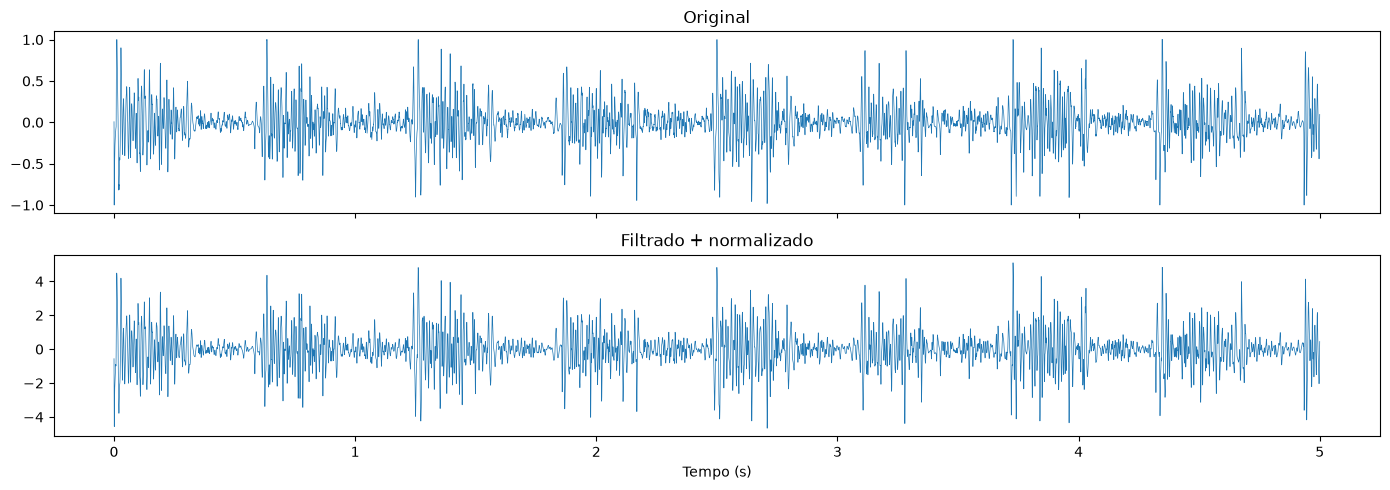

In [34]:
y_raw, _ = librosa.load(ex_forte["path"], sr=SR, duration=WINDOW_SEC)
y_clean = load_clean(ex_forte["path"])[: WINDOW_SEC * SR]

fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
t = np.arange(len(y_raw)) / SR
axes[0].plot(t, y_raw, linewidth=0.5);   axes[0].set_title("Original")
axes[1].plot(t, y_clean, linewidth=0.5); axes[1].set_title("Filtrado + normalizado")
axes[1].set_xlabel("Tempo (s)")
plt.tight_layout(); plt.show()

Comparação auditiva: gravação original e gravação filtrada.

In [35]:
from IPython.display import Audio
display(Audio(y_raw, rate=SR))
display(Audio(y_clean, rate=SR))

### 4.3 Divisão em janelas

Os modelos exigem inputs de tamanho fixo, mas as gravações têm durações entre 5,2 s e 64,5 s. Cada gravação é dividida em janelas de 5 s com sobreposição de 50 % (passo de 2,5 s). Cada janela é um exemplo e herda a label da gravação (`label_rec`).

A sobreposição aumenta o número de exemplos de treino e garante que cada ciclo cardíaco aparece completo em pelo menos uma janela. Na avaliação, as previsões das janelas são agregadas por gravação e depois por paciente.

**Como funcionam as janelas:**

As janelas não correspondem apenas aos primeiros 5 s de cada gravação: a gravação inteira é percorrida com janelas de 5 s que começam a cada 2,5 s, sobrepondo-se em 50 %. Por exemplo, uma gravação de 22,9 s dá origem a 8 janelas:

| Janela | Início (s) | Fim (s) |
|---|---|---|
| 1 | 0,0 | 5,0 |
| 2 | 2,5 | 7,5 |
| 3 | 5,0 | 10,0 |
| ... | ... | ... |
| 8 | 17,5 | 22,5 |

Os 0,4 s finais, que não completam uma janela, são descartados. Cada janela é um exemplo independente para o modelo e herda a label da gravação (`label_rec`).

Como a gravação mais curta do dataset tem 5,15 s, todas as gravações dão origem a pelo menos uma janela completa, pelo que não é necessário recorrer a padding (completar com zeros). Os gráficos da análise exploratória mostram apenas os primeiros 5 s, por uma questão de visualização; no treino é usada a gravação inteira.

In [36]:
HOP_SEC = 2.5       # passo entre janelas, em segundos (50 % de sobreposição)

WIN = WINDOW_SEC * SR          # 20000 amostras
HOP = int(HOP_SEC * SR)        # 10000 amostras

def make_windows(y):
    janelas = []
    for start in range(0, len(y) - WIN + 1, HOP):
        janelas.append(y[start : start + WIN])
    return np.stack(janelas)

Teste numa gravação.

In [37]:
w = make_windows(load_clean(ex_forte["path"]))
print(w.shape, ex_forte["duration"])

(8, 20000) 22.896


Estimativa do número de janelas de cada gravação a partir da sua duração.

In [38]:
rec["n_windows"] = ((rec["duration"] * SR - WIN) // HOP + 1).astype(int)

rec["n_windows"].sum()

np.int64(24198)

Número de janelas por conjunto e classe.

In [39]:
pd.crosstab(rec["split"], rec["label_rec"], values=rec["n_windows"], aggfunc="sum")

label_rec,Absent,Present,Unknown
split,,,
test,2961,589,201
train,13544,2679,807
val,2727,537,153


**Número de janelas por conjunto e classe:**

| | Absent | Present | Unknown | Total |
|---|---:|---:|---:|---:|
| Treino | 13 544 | 2 679 | 807 | 17 030 |
| Validação | 2 727 | 537 | 153 | 3 417 |
| Teste | 2 961 | 589 | 201 | 3 751 |
| **Total** | 19 232 | 3 805 | 1 161 | **24 198** |

**Observações:**
- No treino há cerca de 5 janelas Absent por cada Present e 17 por cada Unknown, o que confirma a necessidade de compensar o desequilíbrio entre classes.
- As amostras finais de cada gravação que não completam uma janela (no máximo 2,5 s) são descartadas. Como o padrão cardíaco se repete em todos os ciclos, esta perda não é relevante.

**Armazenamento dos dados:** guardar todas as janelas ocuparia cerca de 1,9 GB e, com 50 % de sobreposição, cada amostra ficaria guardada duas vezes. Em alternativa:
- cada gravação é processada (filtrada e normalizada) uma única vez e guardada inteira (≈ 1,1 GB);
- é criada uma tabela de janelas, com uma linha por janela (gravação, amostra de início, label e conjunto);
- as janelas são extraídas no momento em que são necessárias, cortando o sinal da gravação.

Desta forma não há duplicação de dados, e alterar o tamanho da janela ou o passo exige apenas reconstruir a tabela de janelas, sem voltar a processar o áudio.

#### Processamento e armazenamento das gravações

Todas as gravações são carregadas, filtradas e normalizadas com a função `load_clean` e guardadas em disco (`signals.pkl`), numa lista em que a posição de cada sinal corresponde à linha da tabela `rec`. Nas execuções seguintes, os sinais são carregados diretamente do ficheiro, evitando repetir o processamento.

In [40]:
import pickle
from tqdm.auto import tqdm

SIGNALS_PATH = "signals.pkl"

if os.path.exists(SIGNALS_PATH):
    with open(SIGNALS_PATH, "rb") as f:
        signals = pickle.load(f)
    print("Sinais carregados do disco.")
else:
    signals = [load_clean(p) for p in tqdm(rec["path"])]
    with open(SIGNALS_PATH, "wb") as f:
        pickle.dump(signals, f)
    print("Sinais processados e guardados.")

print(len(signals), "gravações")

Sinais carregados do disco.
3163 gravações


Verificação de que a ordem dos sinais corresponde à ordem da tabela de gravações.

In [41]:
i = 0
print(rec.loc[i, "path"], rec.loc[i, "duration"], len(signals[i]) / SR)

circor/training_data/13918_AV.wav 10.288 10.288


#### Tabela de janelas

Cada linha corresponde a uma janela de 5 s e guarda a gravação de origem (índice na tabela `rec`), a amostra de início, o paciente, a label e o conjunto. Esta tabela é a base do Dataset usado no treino dos modelos.

In [42]:
linhas = []

for i, row in rec.iterrows():
    n = len(signals[i])
    for start in range(0, n - WIN + 1, HOP):
        linhas.append({
            "rec_idx": i,
            "start": start,
            "patient_id": row["patient_id"],
            "label": row["label_rec"],
            "split": row["split"],
        })

windows = pd.DataFrame(linhas)
print(windows.shape)
windows.head()

(24198, 5)


,rec_idx,start,patient_id,label,split
0,0,0,13918,Absent,train
1,0,10000,13918,Absent,train
2,0,20000,13918,Absent,train
3,1,0,13918,Absent,train
4,1,10000,13918,Absent,train


Número de janelas por conjunto e classe, com totais.

In [43]:
pd.crosstab(windows["split"], windows["label"], margins=True)

label,Absent,Present,Unknown,All
split,,,,
test,2961,589,201,3751
train,13544,2679,807,17030
val,2727,537,153,3417
All,19232,3805,1161,24198


Gravação da tabela de janelas em disco.

In [44]:
windows.to_csv("windows.csv", index=False)

A tabela de janelas tem 24 198 janelas, o mesmo número estimado a partir das durações, o que confirma a consistência entre a tabela de gravações e os sinais processados. A distribuição por conjunto e classe é a apresentada acima.

### 4.4 Escolha dos modelos e extração de features

Foram escolhidos dois modelos que representam o som de formas diferentes:

- **CNN (rede convolucional)** com o **espectrograma mel** de cada janela como input. Na análise exploratória, o sopro aparece como regiões de energia em posições características da representação tempo-frequência, um padrão local que as convoluções estão preparadas para detetar.
- **RNN (GRU)** com a **sequência de MFCCs** de cada janela como input. O que distingue o sopro do ruído é a sua repetição ao longo do tempo, sincronizada com o ciclo cardíaco. A RNN processa o sinal passo a passo e consegue modelar essa dependência temporal.

Os MFCCs (Mel-Frequency Cepstral Coefficients) resumem o espectro mel de cada instante em poucos coeficientes que descrevem a sua forma, o que dá uma representação mais compacta, adequada a uma sequência de entrada para a RNN.

Ambas as representações usam os mesmos parâmetros de análise: janelas de FFT de 512 amostras (≈ 128 ms), avanço de 128 amostras (≈ 32 ms) e frequências até 800 Hz.

In [45]:
N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
N_MFCC = 20
FMAX = 800

Funções que convertem uma janela no espectrograma mel e na sequência de MFCCs.

In [46]:
def to_mel(w):
    S = librosa.feature.melspectrogram(y=w, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
                                       n_mels=N_MELS, fmax=FMAX)
    return librosa.power_to_db(S, ref=np.max).astype(np.float32)

def to_mfcc(w):
    M = librosa.feature.mfcc(y=w, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH,
                             n_mels=N_MELS, fmax=FMAX)
    return M.T.astype(np.float32)

Teste das duas funções numa janela.

In [47]:
rec_idx, start = windows.loc[0, ["rec_idx", "start"]]
w = signals[rec_idx][start : start + WIN]
print(to_mel(w).shape, to_mfcc(w).shape)

(64, 157) (157, 20)


### 4.5 Dataset

O Dataset do PyTorch liga a tabela de janelas aos modelos: para cada janela, extrai o excerto correspondente do sinal processado, calcula a representação de input (espectrograma mel para a CNN, MFCCs para a RNN) e devolve-a juntamente com a label codificada como inteiro (Absent = 0, Present = 1, Unknown = 2). Como a função de extração é um parâmetro, o mesmo Dataset serve para os dois modelos.

In [48]:
from torch.utils.data import Dataset, DataLoader

CLASSES = ["Absent", "Present", "Unknown"]
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}

class HeartDataset(Dataset):
    def __init__(self, windows_df, signals, feature_fn):
        self.df = windows_df.reset_index(drop=True)
        self.signals = signals
        self.feature_fn = feature_fn

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        w = self.signals[row["rec_idx"]][row["start"] : row["start"] + WIN]
        x = torch.from_numpy(self.feature_fn(w))
        y = LABEL2ID[row["label"]]
        return x, y

#### Input da CNN

In [49]:
def to_mel_cnn(w):
    return to_mel(w)[np.newaxis, :, :]     # (64, 157) → (1, 64, 157)

Teste do Dataset e do DataLoader com o input da CNN.

In [50]:
train_win = windows[windows["split"] == "train"]
ds_cnn = HeartDataset(train_win, signals, to_mel_cnn)
dl = DataLoader(ds_cnn, batch_size=32, shuffle=True)

xb, yb = next(iter(dl))
print(len(ds_cnn), xb.shape, yb.shape, yb[:10])

17030 torch.Size([32, 1, 64, 157]) torch.Size([32]) tensor([0, 0, 0, 0, 1, 0, 0, 1, 0, 1])


#### Input da RNN

In [51]:
ds_rnn = HeartDataset(train_win, signals, to_mfcc)
xb, yb = next(iter(DataLoader(ds_rnn, batch_size=32, shuffle=True)))
print(xb.shape)

torch.Size([32, 157, 20])


**Inputs dos modelos:**

Cada janela de 5 s (20 000 amostras) é convertida numa representação diferente para cada modelo. Ambas usam os mesmos parâmetros de análise: o sinal é analisado em blocos de 512 amostras (≈ 128 ms), com um avanço de 128 amostras (≈ 32 ms) entre blocos, o que dá cerca de 157 instantes por janela.

| Modelo | Representação | Forma por janela | Forma por lote (32) |
|---|---|---|---|
| CNN | Espectrograma mel (dB) | 1 × 64 × 157 | 32 × 1 × 64 × 157 |
| RNN | Sequência de MFCCs | 157 × 20 | 32 × 157 × 20 |

- **CNN:** recebe a janela como uma imagem com 1 canal, 64 bandas de frequência (eixo vertical) e 157 instantes (eixo horizontal), em que cada valor é a energia, em dB, daquela banda naquele instante.
- **RNN:** recebe a janela como uma sequência de 157 passos, ordenados no tempo e espaçados de ~32 ms. Em cada passo há um vetor de 20 MFCCs, que resume a forma do espectro naquele instante. A RNN processa os 157 passos por ordem, o que lhe permite modelar a evolução do som ao longo do ciclo cardíaco.

## 5. Modelo 1: CNN

### 5.1 Arquitetura

A CNN recebe o espectrograma mel de cada janela (1 × 64 × 157) e é composta por:

- **3 blocos convolucionais**, cada um com convolução 3×3, batch normalization, ReLU e max pooling 2×2. O número de filtros aumenta de bloco para bloco (16 → 32 → 64), enquanto a dimensão espacial diminui para metade em cada pooling. Os primeiros blocos detetam padrões simples e locais (por exemplo, os S1 e S2); os seguintes combinam-nos em padrões maiores, até cerca de um ciclo cardíaco.
- **Global average pooling**, que resume cada um dos 64 mapas de ativação num único valor ("quanto deste padrão existe na janela"), tornando o modelo independente da posição exata dos eventos no tempo.
- **Dropout (0,3)** e uma **camada linear** que produz 3 logits, um por classe.

Trata-se de um modelo deliberadamente pequeno, que serve de baseline para as melhorias seguintes.

In [52]:
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()

        def bloco(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            bloco(1, 16),
            bloco(16, 32),
            bloco(32, 64),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        x = self.features(x)          # (B, 64, 8, 19)
        x = self.pool(x).flatten(1)   # (B, 64)
        return self.classifier(x)     # (B, 3)

Verificação da forma da saída e do número de parâmetros.

In [53]:
cnn = CNN().to(device)

xb, yb = next(iter(DataLoader(ds_cnn, batch_size=32, shuffle=True)))
out = cnn(xb.to(device))
print(out.shape)

n_params = sum(p.numel() for p in cnn.parameters())
print(f"Parâmetros: {n_params:,}")

torch.Size([32, 3])
Parâmetros: 23,715


### 5.2 Treino

O treino segue o ciclo habitual: para cada lote de 32 janelas, calcula-se a previsão (forward), a loss (cross-entropy), os gradientes (backward) e atualizam-se os pesos com o otimizador Adam (learning rate 0,001). No fim de cada época, o modelo é avaliado no conjunto de validação, sem atualizar os pesos.

Nestas primeiras experiências, a época guardada é a que tem o melhor F1 macro das janelas de validação (média do F1 das três classes, com igual peso). A partir da secção 5.4, a avaliação passa a ser feita por paciente, com a WAmurmur, a métrica do enunciado.

**Experiência 1 (baseline):** treino sem qualquer compensação do desequilíbrio entre classes, para servir de referência.

Funções de treino de uma época e de avaliação no conjunto de validação:

In [54]:
import time
import copy
from sklearn.metrics import f1_score, balanced_accuracy_score

def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()             # limpa os gradientes do lote anterior
        logits = model(xb)                # 1. forward
        loss = loss_fn(logits, yb)        # 2. loss
        loss.backward()                   # 3. backward
        optimizer.step()                  # 4. atualizar os pesos
        total_loss += loss.item() * len(yb)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, preds, labels = 0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total_loss += loss_fn(logits, yb).item() * len(yb)
        preds.append(logits.argmax(1).cpu())
        labels.append(yb.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return {
        "loss": total_loss / len(labels),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "bal_acc": balanced_accuracy_score(labels, preds),
        "preds": preds,
        "labels": labels,
    }

Ciclo de treino completo: repete as épocas, avalia na validação e guarda os pesos da melhor época.

In [55]:
def fit(model, train_loader, val_loader, loss_fn, n_epochs=10, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history, best_f1, best_state = [], -1, None

    for epoch in range(1, n_epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val = evaluate(model, val_loader, loss_fn)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "val_loss": val["loss"], "val_f1": val["f1_macro"], "val_bal_acc": val["bal_acc"]})

        if val["f1_macro"] > best_f1:
            best_f1, best_state = val["f1_macro"], copy.deepcopy(model.state_dict())

        print(f"Época {epoch:2d} | train loss {train_loss:.3f} | val loss {val['loss']:.3f} "
              f"| val F1 {val['f1_macro']:.3f} | val bal acc {val['bal_acc']:.3f} | {time.time()-t0:.0f}s")

    model.load_state_dict(best_state)
    return pd.DataFrame(history)

Treino da experiência 1.

In [56]:
torch.manual_seed(SEED)

val_win = windows[windows["split"] == "val"]
train_loader = DataLoader(HeartDataset(train_win, signals, to_mel_cnn), batch_size=32, shuffle=True)
val_loader = DataLoader(HeartDataset(val_win, signals, to_mel_cnn), batch_size=64, shuffle=False)

cnn = CNN().to(device)
loss_fn = nn.CrossEntropyLoss()
hist_cnn1 = fit(cnn, train_loader, val_loader, loss_fn, n_epochs=10)

Época  1 | train loss 0.531 | val loss 0.475 | val F1 0.452 | val bal acc 0.432 | 185s
Época  2 | train loss 0.456 | val loss 0.444 | val F1 0.469 | val bal acc 0.448 | 171s
Época  3 | train loss 0.431 | val loss 0.627 | val F1 0.438 | val bal acc 0.418 | 176s
Época  4 | train loss 0.420 | val loss 0.529 | val F1 0.445 | val bal acc 0.424 | 176s
Época  5 | train loss 0.408 | val loss 0.416 | val F1 0.498 | val bal acc 0.477 | 175s
Época  6 | train loss 0.397 | val loss 0.454 | val F1 0.473 | val bal acc 0.447 | 175s
Época  7 | train loss 0.390 | val loss 0.410 | val F1 0.498 | val bal acc 0.472 | 175s
Época  8 | train loss 0.384 | val loss 0.387 | val F1 0.520 | val bal acc 0.504 | 176s
Época  9 | train loss 0.377 | val loss 0.404 | val F1 0.502 | val bal acc 0.482 | 175s
Época 10 | train loss 0.370 | val loss 0.396 | val F1 0.505 | val bal acc 0.478 | 175s


Curvas de loss e das métricas de validação ao longo das épocas.

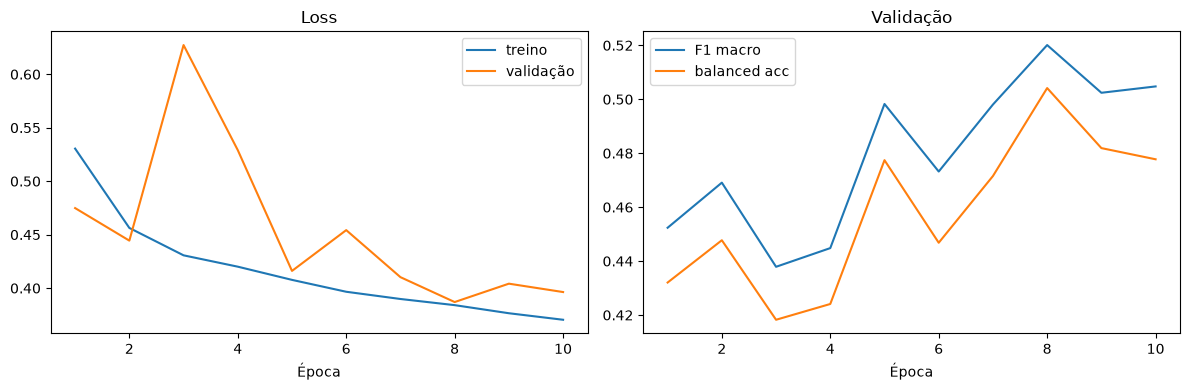

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_cnn1["epoch"], hist_cnn1["train_loss"], label="treino")
axes[0].plot(hist_cnn1["epoch"], hist_cnn1["val_loss"], label="validação")
axes[0].set_title("Loss"); axes[0].set_xlabel("Época"); axes[0].legend()
axes[1].plot(hist_cnn1["epoch"], hist_cnn1["val_f1"], label="F1 macro")
axes[1].plot(hist_cnn1["epoch"], hist_cnn1["val_bal_acc"], label="balanced acc")
axes[1].set_title("Validação"); axes[1].set_xlabel("Época"); axes[1].legend()
plt.tight_layout(); plt.show()

Matriz de confusão e métricas por classe na validação, ao nível das janelas.

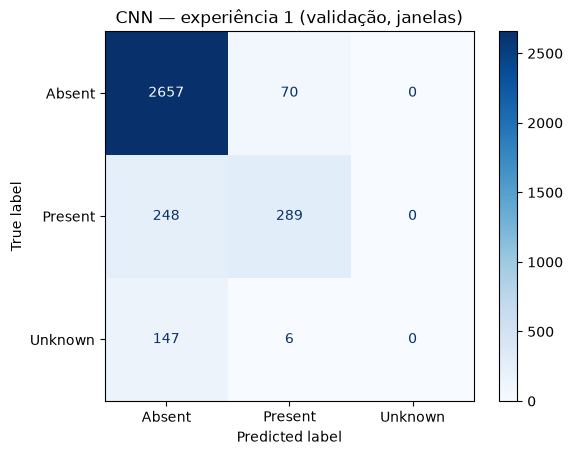

              precision    recall  f1-score   support

      Absent      0.871     0.974     0.920      2727
     Present      0.792     0.538     0.641       537
     Unknown      0.000     0.000     0.000       153

    accuracy                          0.862      3417
   macro avg      0.554     0.504     0.520      3417
weighted avg      0.819     0.862     0.835      3417



/Users/Bernardo/miniconda3/envs/ml2arm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/Bernardo/miniconda3/envs/ml2arm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/Bernardo/miniconda3/envs/ml2arm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

In [58]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

val = evaluate(cnn, val_loader, loss_fn)
ConfusionMatrixDisplay(confusion_matrix(val["labels"], val["preds"]), display_labels=CLASSES).plot(cmap="Blues")
plt.title("CNN — experiência 1 (validação, janelas)")
plt.show()

print(classification_report(val["labels"], val["preds"], target_names=CLASSES, digits=3))

**Resultados da experiência 1 (baseline, validação ao nível das janelas):**

| Classe | Precisão | Recall | F1 |
|---|---:|---:|---:|
| Absent | 0,871 | 0,974 | 0,920 |
| Present | 0,792 | 0,538 | 0,641 |
| Unknown | 0,000 | 0,000 | 0,000 |
| **Macro** | 0,554 | 0,504 | **0,520** |

- O modelo deteta pouco mais de metade das janelas com sopro (recall de Present de 0,538): 248 das 537 são classificadas como Absent, o tipo de erro clinicamente mais grave.
- A classe Unknown nunca é reconhecida: o modelo não previu Unknown uma única vez em toda a validação, e quase todas estas janelas (147 de 153) foram classificadas como Absent. Sem compensação, o modelo ignora a classe com menos exemplos.
- A accuracy (86,2 %) é enganadora, porque esconde a falha total numa das classes; o F1 macro (0,520) reflete melhor o desempenho.
- A loss de treino desce de forma consistente (0,531 → 0,370). A de validação oscila bastante nas primeiras épocas (chega a 0,627 na época 3) e só depois estabiliza perto de 0,40.

Próximo passo: compensar o desequilíbrio entre classes (experiência 2).

### 5.3 Pré-cálculo das features

Na experiência 1, cada época demorou cerca de 3 minutos, quase todos gastos a recalcular os espectrogramas, que são iguais em todas as épocas. Para acelerar as experiências seguintes, o espectrograma mel e os MFCCs de todas as janelas são calculados uma única vez e guardados em disco (`mel.npy`, ≈ 1 GB, e `mfcc.npy`, ≈ 0,3 GB). A ordem das features corresponde à ordem das linhas da tabela `windows`.

In [59]:
MEL_PATH, MFCC_PATH = "mel.npy", "mfcc.npy"

if os.path.exists(MEL_PATH) and os.path.exists(MFCC_PATH):
    X_mel = np.load(MEL_PATH)
    X_mfcc = np.load(MFCC_PATH)
    print("Features carregadas do disco.")
else:
    N = len(windows)
    X_mel = np.zeros((N, 1, N_MELS, 157), dtype=np.float32)
    X_mfcc = np.zeros((N, 157, N_MFCC), dtype=np.float32)

    for j, (r, s) in enumerate(tqdm(zip(windows["rec_idx"], windows["start"]), total=N)):
        w = signals[r][s : s + WIN]
        S = librosa.feature.melspectrogram(y=w, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
                                           n_mels=N_MELS, fmax=FMAX)
        X_mel[j, 0] = librosa.power_to_db(S, ref=np.max)
        X_mfcc[j] = librosa.feature.mfcc(S=librosa.power_to_db(S), n_mfcc=N_MFCC).T

    np.save(MEL_PATH, X_mel)
    np.save(MFCC_PATH, X_mfcc)
    print("Features calculadas e guardadas.")

print(X_mel.shape, X_mfcc.shape)

Features carregadas do disco.
(24198, 1, 64, 157) (24198, 157, 20)


Verificação de que as features guardadas são iguais às calculadas a partir do sinal.

In [60]:
j = 100
r, s = windows.loc[j, ["rec_idx", "start"]]
w = signals[r][s : s + WIN]
print(np.allclose(X_mel[j], to_mel_cnn(w)), np.allclose(X_mfcc[j], to_mfcc(w), atol=1e-4))

True True


#### Dataset com features pré-calculadas

Com as features já calculadas, o Dataset passa a ir buscá-las diretamente aos arrays guardados (`X_mel` para a CNN, `X_mfcc` para a RNN), em vez de as calcular a partir do sinal em cada época. Cada conjunto (treino, validação e teste) é definido pela lista das janelas que lhe pertencem. As labels de todas as janelas são convertidas para inteiros (Absent = 0, Present = 1, Unknown = 2).

In [61]:
y_all = windows["label"].map(LABEL2ID).values

class FeatureDataset(Dataset):
    def __init__(self, X, y, idx):
        self.X, self.y, self.idx = X, y, np.asarray(idx)

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        return torch.from_numpy(self.X[j]), int(self.y[j])

train_idx = windows.index[windows["split"] == "train"]
val_idx = windows.index[windows["split"] == "val"]
test_idx = windows.index[windows["split"] == "test"]

**Experiência 2: class weights.** Para compensar o desequilíbrio, cada classe recebe na loss um peso inversamente proporcional à sua frequência no treino: peso(c) = N / (K × N_c), em que N é o número de janelas de treino, K o número de classes e N_c o número de janelas da classe c. Os pesos resultantes são 0,42 (Absent), 2,12 (Present) e 7,03 (Unknown): um erro numa janela Unknown penaliza o modelo cerca de 17 vezes mais do que um erro numa janela Absent. Todas as outras condições são iguais às da experiência 1.

In [62]:
counts = np.bincount(y_all[train_idx], minlength=3)
class_weights = len(train_idx) / (3 * counts)
print(dict(zip(CLASSES, class_weights.round(2))))

train_loader = DataLoader(FeatureDataset(X_mel, y_all, train_idx), batch_size=32, shuffle=True)
val_loader = DataLoader(FeatureDataset(X_mel, y_all, val_idx), batch_size=64, shuffle=False)

torch.manual_seed(SEED)
cnn2 = CNN().to(device)
loss_fn_w = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device))
hist_cnn2 = fit(cnn2, train_loader, val_loader, loss_fn_w, n_epochs=10)

{'Absent': np.float64(0.42), 'Present': np.float64(2.12), 'Unknown': np.float64(7.03)}
Época  1 | train loss 0.952 | val loss 0.897 | val F1 0.406 | val bal acc 0.547 | 49s
Época  2 | train loss 0.852 | val loss 0.868 | val F1 0.455 | val bal acc 0.568 | 48s
Época  3 | train loss 0.808 | val loss 0.660 | val F1 0.550 | val bal acc 0.552 | 47s
Época  4 | train loss 0.793 | val loss 0.719 | val F1 0.513 | val bal acc 0.525 | 46s
Época  5 | train loss 0.773 | val loss 0.748 | val F1 0.503 | val bal acc 0.630 | 47s
Época  6 | train loss 0.750 | val loss 0.719 | val F1 0.533 | val bal acc 0.598 | 48s
Época  7 | train loss 0.740 | val loss 0.668 | val F1 0.561 | val bal acc 0.602 | 47s
Época  8 | train loss 0.726 | val loss 0.712 | val F1 0.536 | val bal acc 0.647 | 47s
Época  9 | train loss 0.716 | val loss 0.833 | val F1 0.475 | val bal acc 0.649 | 48s
Época 10 | train loss 0.703 | val loss 0.742 | val F1 0.528 | val bal acc 0.646 | 48s


Matriz de confusão e métricas por classe da experiência 2 (validação, janelas).

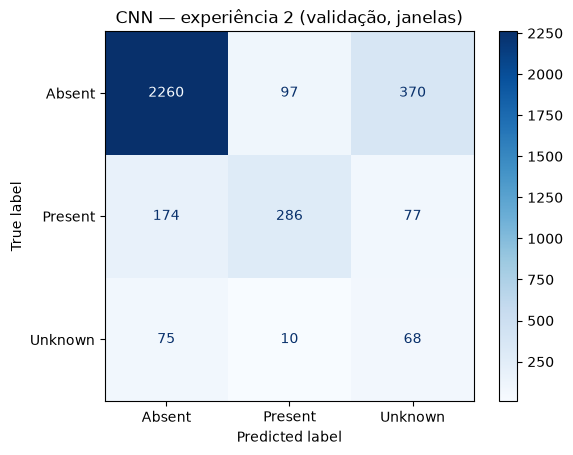

              precision    recall  f1-score   support

      Absent      0.901     0.829     0.863      2727
     Present      0.728     0.533     0.615       537
     Unknown      0.132     0.444     0.204       153

    accuracy                          0.765      3417
   macro avg      0.587     0.602     0.561      3417
weighted avg      0.839     0.765     0.795      3417



In [63]:
val2 = evaluate(cnn2, val_loader, loss_fn_w)
ConfusionMatrixDisplay(confusion_matrix(val2["labels"], val2["preds"]), display_labels=CLASSES).plot(cmap="Blues")
plt.title("CNN — experiência 2 (validação, janelas)")
plt.show()
print(classification_report(val2["labels"], val2["preds"], target_names=CLASSES, digits=3))

**Resultados da experiência 2 (class weights, validação ao nível das janelas):**

| Classe | Recall exp. 1 | Recall exp. 2 | Precisão exp. 2 |
|---|---:|---:|---:|
| Absent | 0,974 | 0,829 | 0,901 |
| Present | 0,538 | 0,533 | 0,728 |
| Unknown | 0,000 | 0,444 | 0,132 |
| **F1 macro** | 0,520 | **0,561** | |

- Os class weights fizeram o modelo passar a reconhecer a classe Unknown (recall de 0 para 0,444), mas com uma precisão muito baixa (0,132): o modelo prevê Unknown em 515 janelas, quando só 153 o são. Aprende que, na dúvida, é preferível responder Unknown, porque o peso desta classe (7,03) torna os seus erros muito penalizadores.
- Esse ganho foi feito sobretudo à custa da classe Absent: 370 janelas Absent passaram a ser classificadas como Unknown, e o recall de Absent desceu de 0,974 para 0,829. O recall de Present ficou praticamente igual (0,538 → 0,533).
- O F1 macro subiu (0,520 → 0,561), mas esta métrica dá o mesmo peso às três classes e não diz se a troca compensa do ponto de vista clínico. Essa questão é analisada a seguir, com a avaliação por paciente.
- O treino é mais rápido com as features pré-calculadas: cerca de 47 s por época, contra cerca de 175 s na experiência 1.

### 5.4 Avaliação por paciente

O objetivo final é classificar pacientes, não janelas. As previsões são agregadas em dois passos:

1. **Janelas → gravação:** média das probabilidades (softmax) das janelas de cada gravação; a classe com maior probabilidade média é a previsão da gravação. A média reduz o efeito de janelas isoladas com ruído.
2. **Gravações → paciente**, com uma regra hierárquica que segue a definição da label Murmur no dataset (um paciente é Present se o sopro foi detetado em pelo menos uma gravação):
   - se alguma gravação for prevista como Present, o paciente é Present;
   - caso contrário, se alguma for prevista como Unknown, o paciente é Unknown;
   - caso contrário, o paciente é Absent.

Para comparação, é também calculada uma regra simples: a média das probabilidades de todas as janelas do paciente.

A avaliação por paciente usa a label original (Murmur), e não a label por gravação usada no treino.

**Métrica principal: WAmurmur.** Tal como pedido no enunciado, os modelos são avaliados pela weighted accuracy do PhysioNet Challenge 2022, calculada por paciente:

$$WA_{murmur} = \frac{5\,c_P + 3\,c_U + c_A}{5\,n_P + 3\,n_U + n_A}$$

em que $c_P$, $c_U$ e $c_A$ são os pacientes Present, Unknown e Absent corretamente classificados, e $n_P$, $n_U$ e $n_A$ o total de pacientes de cada classe. Esta expressão é equivalente à do enunciado: o numerador soma a diagonal da matriz de confusão com os pesos 5, 3 e 1, e o denominador soma todos os pacientes de cada classe real com os mesmos pesos. Os pesos refletem a importância clínica: acertar um Present vale 5, um Unknown 3 e um Absent 1. No resto do notebook, "accuracy ponderada" refere-se sempre a esta métrica.

Função que devolve as probabilidades de cada janela:

In [64]:
@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    probs = []
    for xb, _ in loader:
        probs.append(torch.softmax(model(xb.to(device)), dim=1).cpu())
    return torch.cat(probs).numpy()

Cálculo da WAmurmur e função que agrega as previsões por paciente (regra hierárquica e regra da média) e imprime os resultados.

In [65]:
def weighted_accuracy(y_true, y_pred):
    pesos = {"Present": 5, "Unknown": 3, "Absent": 1}
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    acertos = sum(pesos[t] for t, p in zip(y_true, y_pred) if t == p)
    total = sum(pesos[t] for t in y_true)
    return acertos / total

def patient_eval(probs, idx):
    w = windows.loc[idx, ["rec_idx", "patient_id"]].copy()
    w[CLASSES] = probs

    # 1. janelas → gravação (média das probabilidades)
    rec_pred = w.groupby("rec_idx")[CLASSES].mean().idxmax(axis=1)
    rec_pred = pd.DataFrame({"pred": rec_pred, "patient_id": rec.loc[rec_pred.index, "patient_id"]})

    # 2a. gravações → paciente (regra hierárquica)
    def hierarquica(preds):
        if "Present" in preds.values: return "Present"
        if "Unknown" in preds.values: return "Unknown"
        return "Absent"
    pat_hier = rec_pred.groupby("patient_id")["pred"].apply(hierarquica)

    # 2b. todas as janelas do paciente → paciente (média)
    pat_mean = w.groupby("patient_id")[CLASSES].mean().idxmax(axis=1)

    # label verdadeira do paciente
    y_true = labels.set_index("Patient ID").loc[pat_hier.index, "Murmur"]

    for nome, pred in [("Hierárquica", pat_hier), ("Média", pat_mean.loc[pat_hier.index])]:
        print(f"=== Regra {nome} — {len(y_true)} pacientes ===")
        print(classification_report(y_true, pred, labels=CLASSES, digits=3, zero_division=0))
        print(f"Accuracy ponderada: {weighted_accuracy(y_true, pred):.3f}\n")
    return y_true, pat_hier, pat_mean

Avaliação por paciente das experiências 1 e 2, na validação.

In [66]:
val_loader_eval = DataLoader(FeatureDataset(X_mel, y_all, val_idx), batch_size=64, shuffle=False)

print("########## EXPERIÊNCIA 1 ##########")
_ = patient_eval(predict_probs(cnn, val_loader_eval), val_idx)
print("########## EXPERIÊNCIA 2 ##########")
_ = patient_eval(predict_probs(cnn2, val_loader_eval), val_idx)

########## EXPERIÊNCIA 1 ##########
=== Regra Hierárquica — 138 pacientes ===
              precision    recall  f1-score   support

      Absent      0.850     0.990     0.915       103
     Present      0.944     0.680     0.791        25
     Unknown      0.000     0.000     0.000        10

    accuracy                          0.862       138
   macro avg      0.598     0.557     0.568       138
weighted avg      0.806     0.862     0.826       138

Accuracy ponderada: 0.725

=== Regra Média — 138 pacientes ===
              precision    recall  f1-score   support

      Absent      0.824     1.000     0.904       103
     Present      1.000     0.520     0.684        25
     Unknown      0.000     0.000     0.000        10

    accuracy                          0.841       138
   macro avg      0.608     0.507     0.529       138
weighted avg      0.796     0.841     0.798       138

Accuracy ponderada: 0.651

########## EXPERIÊNCIA 2 ##########
=== Regra Hierárquica — 138 pacien

**Resultados por paciente (validação, 138 pacientes: 103 Absent, 25 Present e 10 Unknown):**

| Experiência | Regra | Recall Present | Recall Unknown | Recall Absent | F1 macro | Accuracy ponderada |
|---|---|---:|---:|---:|---:|---:|
| 1 (baseline) | Hierárquica | 0,680 | 0,000 | 0,990 | 0,568 | **0,725** |
| 1 (baseline) | Média | 0,520 | 0,000 | 1,000 | 0,529 | 0,651 |
| 2 (class weights) | Hierárquica | 0,680 | 0,600 | 0,748 | 0,614 | 0,698 |
| 2 (class weights) | Média | 0,520 | 0,500 | 0,903 | 0,640 | 0,671 |

- A agregação por paciente melhora a deteção de sopros: na experiência 1, o recall de Present passa de 0,538 (janelas) para 0,680 (pacientes, regra hierárquica), porque basta o sopro ser detetado numa das gravações do paciente.
- A regra hierárquica privilegia a deteção de sopros (17 dos 25 pacientes Present, contra 13 com a regra da média), enquanto a regra da média é mais conservadora. A regra hierárquica é adotada por seguir a definição da label no dataset e pela prioridade clínica de não falhar sopros; nas duas experiências é também a que tem melhor WAmurmur.
- O F1 macro dá o mesmo peso a todas as classes e é muito sensível à classe Unknown, que tem apenas 10 pacientes na validação (cada paciente vale 10 pontos de recall). A WAmurmur, que atribui pesos de 5, 3 e 1 aos acertos em Present, Unknown e Absent, reflete melhor a importância clínica de cada classe.
- Com a WAmurmur, o baseline com regra hierárquica é o melhor modelo até agora (0,725). Os class weights da experiência 2 pioraram o resultado (0,698): o modelo acerta 6 dos 10 pacientes Unknown, mas deixa de acertar 25 pacientes Absent (o recall de Absent desce de 0,990 para 0,748), na sua maioria desviados para Unknown. O F1 macro sugeria o contrário.
- Com 25 pacientes Present e 10 Unknown na validação, diferenças de poucos pacientes alteram bastante as métricas; as comparações devem ser interpretadas com cautela.

**Experiência 3: class weights suavizados.** Na experiência 2, o peso da classe Unknown (7,03) levou o modelo a prever Unknown em excesso. Nesta experiência usa-se a raiz quadrada dos pesos anteriores (Absent ≈ 0,65, Present ≈ 1,46, Unknown ≈ 2,65), compensando o desequilíbrio de forma mais moderada. Todas as outras condições são iguais às das experiências anteriores.

In [67]:
class_weights_sqrt = np.sqrt(class_weights)
print(dict(zip(CLASSES, class_weights_sqrt.round(2))))

torch.manual_seed(SEED)
cnn3 = CNN().to(device)
loss_fn_sqrt = nn.CrossEntropyLoss(weight=torch.tensor(class_weights_sqrt, dtype=torch.float32).to(device))
hist_cnn3 = fit(cnn3, train_loader, val_loader, loss_fn_sqrt, n_epochs=10)

print("########## EXPERIÊNCIA 3 ##########")
_ = patient_eval(predict_probs(cnn3, val_loader_eval), val_idx)

{'Absent': np.float64(0.65), 'Present': np.float64(1.46), 'Unknown': np.float64(2.65)}
Época  1 | train loss 0.799 | val loss 0.615 | val F1 0.474 | val bal acc 0.469 | 49s
Época  2 | train loss 0.703 | val loss 0.593 | val F1 0.548 | val bal acc 0.524 | 48s
Época  3 | train loss 0.664 | val loss 0.728 | val F1 0.491 | val bal acc 0.480 | 48s
Época  4 | train loss 0.650 | val loss 0.630 | val F1 0.463 | val bal acc 0.442 | 47s
Época  5 | train loss 0.632 | val loss 0.606 | val F1 0.546 | val bal acc 0.535 | 47s
Época  6 | train loss 0.618 | val loss 0.564 | val F1 0.552 | val bal acc 0.522 | 46s
Época  7 | train loss 0.607 | val loss 0.697 | val F1 0.523 | val bal acc 0.484 | 47s
Época  8 | train loss 0.597 | val loss 0.515 | val F1 0.586 | val bal acc 0.559 | 47s
Época  9 | train loss 0.589 | val loss 0.564 | val F1 0.585 | val bal acc 0.591 | 48s
Época 10 | train loss 0.578 | val loss 0.528 | val F1 0.585 | val bal acc 0.555 | 49s
########## EXPERIÊNCIA 3 ##########
=== Regra Hierárq

**Resultados da experiência 3 (class weights suavizados, por paciente, regra hierárquica):**

| Experiência | Recall Present | Recall Unknown | Recall Absent | Accuracy ponderada |
|---|---:|---:|---:|---:|
| 1 (baseline) | 0,680 | 0,000 | 0,990 | 0,725 |
| 2 (class weights) | 0,680 | 0,600 | 0,748 | 0,698 |
| 3 (class weights suavizados) | **0,720** | 0,200 | 0,942 | **0,748** |

- Os pesos suavizados são o melhor compromisso: em relação ao baseline, o modelo deteta mais um paciente Present (18 de 25) e reconhece 2 dos 10 pacientes Unknown, perdendo 5 pacientes Absent (o recall de Absent desce de 0,990 para 0,942).
- Ao contrário da experiência 2, o modelo prevê Unknown com parcimónia: fá-lo apenas em 3 pacientes, e acerta em 2.
- A WAmurmur sobe de 0,725 para 0,748. A diferença corresponde a 6 pontos em 258, pouco mais do que um paciente Present, pelo que está dentro da variabilidade esperada com um conjunto de validação pequeno. Os pesos suavizados são adotados nas experiências seguintes.

### 5.5 Seleção do modelo pela métrica por paciente

Nas experiências anteriores, a melhor época era escolhida pelo F1 macro das janelas, que não é a métrica final do problema. A partir daqui, no fim de cada época as previsões de validação são agregadas por paciente (regra hierárquica) e a época guardada é a que tem a melhor accuracy ponderada. Além disso, o treino pára quando esta métrica não melhora durante 5 épocas consecutivas (early stopping com paciência de 5), o que permite treinar mais épocas sem risco de ficar com um modelo pior.

Funções de previsão e de relatório por paciente, agora separadas, para poderem ser usadas durante o treino:

In [68]:
def patient_predict(probs, idx):
    w = windows.loc[idx, ["rec_idx", "patient_id"]].copy()
    w[CLASSES] = probs

    rec_pred = w.groupby("rec_idx")[CLASSES].mean().idxmax(axis=1)
    rec_pred = pd.DataFrame({"pred": rec_pred, "patient_id": rec.loc[rec_pred.index, "patient_id"]})

    def hierarquica(preds):
        if "Present" in preds.values: return "Present"
        if "Unknown" in preds.values: return "Unknown"
        return "Absent"

    y_pred = rec_pred.groupby("patient_id")["pred"].apply(hierarquica)
    y_true = labels.set_index("Patient ID").loc[y_pred.index, "Murmur"]
    return y_true, y_pred

def patient_report(y_true, y_pred, titulo):
    print(f"=== {titulo} — {len(y_true)} pacientes ===")
    print(classification_report(y_true, y_pred, labels=CLASSES, digits=3, zero_division=0))
    print(f"WAmurmur (accuracy ponderada): {weighted_accuracy(y_true, y_pred):.3f}\n")

Nova versão da avaliação, que devolve também as probabilidades de cada janela.

In [69]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, probs, labels_ = 0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total_loss += loss_fn(logits, yb).item() * len(yb)
        probs.append(torch.softmax(logits, dim=1).cpu())
        labels_.append(yb.cpu())
    probs, labels_ = torch.cat(probs).numpy(), torch.cat(labels_).numpy()
    preds = probs.argmax(1)
    return {
        "loss": total_loss / len(labels_),
        "f1_macro": f1_score(labels_, preds, average="macro"),
        "bal_acc": balanced_accuracy_score(labels_, preds),
        "preds": preds,
        "labels": labels_,
        "probs": probs,
    }

Nova versão do ciclo de treino: escolhe a melhor época pela WAmurmur por paciente e pára se não houver melhoria.

In [70]:
def fit(model, train_loader, val_loader, val_idx, loss_fn, n_epochs=25, lr=1e-3, patience=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history, best_wacc, best_state, sem_melhoria = [], -1, None, 0

    for epoch in range(1, n_epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val = evaluate(model, val_loader, loss_fn)

        y_true, y_pred = patient_predict(val["probs"], val_idx)
        wacc = weighted_accuracy(y_true, y_pred)
        rec_present = ((y_true == "Present") & (y_pred == "Present")).sum() / (y_true == "Present").sum()

        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val["loss"],
                        "val_f1_win": val["f1_macro"], "val_wacc": wacc, "val_rec_present": rec_present})

        if wacc > best_wacc:
            best_wacc, best_state, sem_melhoria = wacc, copy.deepcopy(model.state_dict()), 0
            marca = " *"
        else:
            sem_melhoria += 1
            marca = ""

        print(f"Época {epoch:2d} | train loss {train_loss:.3f} | val loss {val['loss']:.3f} "
              f"| F1 janelas {val['f1_macro']:.3f} | wacc pac. {wacc:.3f} "
              f"| recall Present pac. {rec_present:.3f} | {time.time()-t0:.0f}s{marca}")

        if sem_melhoria >= patience:
            print(f"Early stopping: {patience} épocas sem melhoria.")
            break

    model.load_state_dict(best_state)
    print(f"Melhor accuracy ponderada (validação): {best_wacc:.3f}")
    return pd.DataFrame(history)

Repetição das experiências 1 e 3 com o novo critério (experiências 1b e 3b).

In [71]:
torch.manual_seed(SEED)
cnn1b = CNN().to(device)
hist_cnn1b = fit(cnn1b, train_loader, val_loader, val_idx, nn.CrossEntropyLoss())

torch.manual_seed(SEED)
cnn3b = CNN().to(device)
hist_cnn3b = fit(cnn3b, train_loader, val_loader, val_idx, loss_fn_sqrt)

Época  1 | train loss 0.531 | val loss 0.475 | F1 janelas 0.452 | wacc pac. 0.593 | recall Present pac. 0.400 | 49s *
Época  2 | train loss 0.456 | val loss 0.444 | F1 janelas 0.469 | wacc pac. 0.632 | recall Present pac. 0.480 | 48s *
Época  3 | train loss 0.431 | val loss 0.627 | F1 janelas 0.438 | wacc pac. 0.574 | recall Present pac. 0.360 | 48s
Época  4 | train loss 0.420 | val loss 0.529 | F1 janelas 0.445 | wacc pac. 0.593 | recall Present pac. 0.400 | 48s
Época  5 | train loss 0.408 | val loss 0.416 | F1 janelas 0.498 | wacc pac. 0.705 | recall Present pac. 0.640 | 49s *
Época  6 | train loss 0.397 | val loss 0.454 | F1 janelas 0.473 | wacc pac. 0.612 | recall Present pac. 0.440 | 49s
Época  7 | train loss 0.390 | val loss 0.410 | F1 janelas 0.498 | wacc pac. 0.671 | recall Present pac. 0.560 | 49s
Época  8 | train loss 0.384 | val loss 0.387 | F1 janelas 0.520 | wacc pac. 0.725 | recall Present pac. 0.680 | 49s *
Época  9 | train loss 0.377 | val loss 0.404 | F1 janelas 0.502 

Relatório por paciente da experiência 3b.

In [72]:
y_true, y_pred = patient_predict(evaluate(cnn3b, val_loader, loss_fn_sqrt)["probs"], val_idx)
patient_report(y_true, y_pred, "CNN — experiência 3b (validação)")

=== CNN — experiência 3b (validação) — 138 pacientes ===
              precision    recall  f1-score   support

      Absent      0.891     0.951     0.920       103
     Present      0.810     0.680     0.739        25
     Unknown      0.571     0.400     0.471        10

    accuracy                          0.862       138
   macro avg      0.757     0.677     0.710       138
weighted avg      0.853     0.862     0.855       138

WAmurmur (accuracy ponderada): 0.756



**Resultados com seleção pela métrica por paciente (validação):**

| Experiência | Melhor época | Accuracy ponderada | Recall Present |
|---|---:|---:|---:|
| 1b (baseline) | 17 | 0,752 | 0,760 |
| 3b (class weights suavizados) | 2 | 0,756 | 0,680 |

- Com a mesma semente aleatória, as primeiras 10 épocas da experiência 1b reproduzem exatamente as da experiência 1, o que confirma a reprodutibilidade dos resultados.
- As duas experiências empatam na accuracy ponderada. No entanto, a métrica oscila muito de época para época: na experiência 1b varia entre 0,574 e 0,752, e o recall de Present chega a cair de 0,600 para 0,360 numa só época (da 10 para a 11). Na experiência 3b, a melhor época foi a segunda; na seguinte, a métrica caiu de 0,756 para 0,605, e o treino parou por early stopping na época 7.
- Esta instabilidade tem duas causas: o conjunto de validação é pequeno (25 pacientes Present), pelo que mudar a previsão de poucos pacientes altera muito a métrica; e o treino parece instável, com saltos na loss de validação, típicos de um learning rate demasiado elevado.
- Com esta variabilidade, as diferenças entre configurações não são distinguíveis, e o valor da melhor época é uma estimativa otimista. O passo seguinte é estabilizar o treino antes de testar outras melhorias.

**Experiência 4: learning rate mais baixo.** Para tentar estabilizar o treino, o learning rate passa de 0,001 para 0,0003, com mais paciência no early stopping (8 épocas em vez de 5), porque o modelo aprende mais devagar. Mantêm-se os class weights suavizados.

In [73]:
torch.manual_seed(SEED)
cnn4 = CNN().to(device)
hist_cnn4 = fit(cnn4, train_loader, val_loader, val_idx, loss_fn_sqrt, n_epochs=30, lr=3e-4, patience=8)

Época  1 | train loss 0.845 | val loss 0.753 | F1 janelas 0.414 | wacc pac. 0.678 | recall Present pac. 0.920 | 57s *
Época  2 | train loss 0.738 | val loss 0.613 | F1 janelas 0.502 | wacc pac. 0.636 | recall Present pac. 0.440 | 55s
Época  3 | train loss 0.700 | val loss 0.604 | F1 janelas 0.525 | wacc pac. 0.663 | recall Present pac. 0.520 | 55s
Época  4 | train loss 0.686 | val loss 0.629 | F1 janelas 0.481 | wacc pac. 0.612 | recall Present pac. 0.440 | 56s
Época  5 | train loss 0.669 | val loss 0.590 | F1 janelas 0.557 | wacc pac. 0.748 | recall Present pac. 0.720 | 55s *
Época  6 | train loss 0.657 | val loss 0.588 | F1 janelas 0.510 | wacc pac. 0.636 | recall Present pac. 0.440 | 56s
Época  7 | train loss 0.647 | val loss 0.564 | F1 janelas 0.546 | wacc pac. 0.733 | recall Present pac. 0.640 | 56s
Época  8 | train loss 0.638 | val loss 0.547 | F1 janelas 0.535 | wacc pac. 0.705 | recall Present pac. 0.600 | 56s
Época  9 | train loss 0.629 | val loss 0.611 | F1 janelas 0.535 | wa

Comparação das curvas de validação com os dois learning rates.

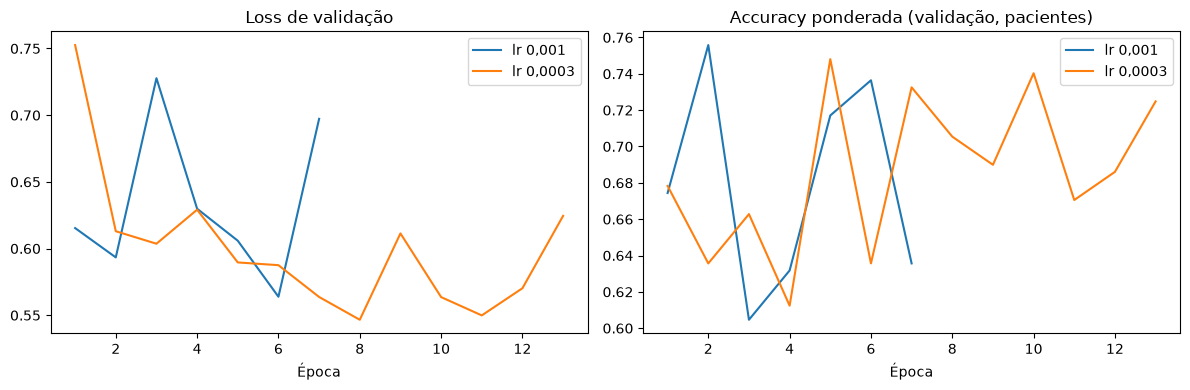

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for h, nome in [(hist_cnn3b, "lr 0,001"), (hist_cnn4, "lr 0,0003")]:
    axes[0].plot(h["epoch"], h["val_loss"], label=nome)
    axes[1].plot(h["epoch"], h["val_wacc"], label=nome)
axes[0].set_title("Loss de validação"); axes[1].set_title("Accuracy ponderada (validação, pacientes)")
for ax in axes: ax.set_xlabel("Época"); ax.legend()
plt.tight_layout(); plt.show()

**Resultados da experiência 4 (learning rate 0,0003, paciência 8, class weights suavizados):**

| Experiência | Melhor época | Accuracy ponderada | Recall Present |
|---|---:|---:|---:|
| 1b (baseline, lr 0,001) | 17 | 0,752 | 0,760 |
| 3b (pesos suavizados, lr 0,001) | 2 | 0,756 | 0,680 |
| 4 (pesos suavizados, lr 0,0003) | 5 | 0,748 | 0,720 |

- Reduzir o learning rate não estabilizou o treino: a accuracy ponderada continua a oscilar entre 0,612 e 0,748, e o recall de Present entre 0,440 e 0,920. Da época 5 para a 6, por exemplo, a métrica cai de 0,748 para 0,636.
- As três configurações têm o mesmo valor máximo (0,75), sempre atingido numa época isolada.
- A métrica por paciente é muito sensível a pequenas mudanças no modelo. A regra hierárquica amplifica-as: basta que uma das cerca de quatro gravações de um paciente Absent passe a ser prevista como Present para o paciente ser mal classificado. E, com 25 pacientes Present na validação, cada um vale quase 2 % da métrica. Parte da instabilidade resulta, portanto, da agregação e do pequeno número de pacientes, e não apenas do treino.

**Experiência 5: learning rate com decaimento em cosseno.** Nas experiências anteriores, a métrica oscilava muito até ao fim do treino. Nesta experiência, o learning rate começa em 0,001 e diminui ao longo das 20 épocas segundo uma curva em cosseno, até 0,00001. No início, os passos grandes permitem aprender depressa; no fim, os passos pequenos fazem o modelo estabilizar, em vez de oscilar entre soluções diferentes. O early stopping é desligado, para o treino chegar à fase de learning rate baixo; continua a ser guardada a época com melhor accuracy ponderada. Mantêm-se os class weights suavizados.

Versão final do ciclo de treino, com a opção de decaimento em cosseno:

In [75]:
def fit(model, train_loader, val_loader, val_idx, loss_fn, n_epochs=25, lr=1e-3,
        patience=5, cosine=False):                                               # NOVO
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=lr / 100)
                 if cosine else None)                                            # NOVO
    history, best_wacc, best_state, sem_melhoria = [], -1, None, 0

    for epoch in range(1, n_epochs + 1):
        t0 = time.time()
        lr_atual = optimizer.param_groups[0]["lr"]                               # NOVO
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val = evaluate(model, val_loader, loss_fn)
        if scheduler: scheduler.step()                                           # NOVO

        y_true, y_pred = patient_predict(val["probs"], val_idx)
        wacc = weighted_accuracy(y_true, y_pred)
        rec_present = ((y_true == "Present") & (y_pred == "Present")).sum() / (y_true == "Present").sum()

        history.append({"epoch": epoch, "lr": lr_atual, "train_loss": train_loss, "val_loss": val["loss"],
                        "val_f1_win": val["f1_macro"], "val_wacc": wacc, "val_rec_present": rec_present})

        if wacc > best_wacc:
            best_wacc, best_state, sem_melhoria = wacc, copy.deepcopy(model.state_dict()), 0
            marca = " *"
        else:
            sem_melhoria += 1
            marca = ""

        print(f"Época {epoch:2d} | lr {lr_atual:.5f} | train loss {train_loss:.3f} | val loss {val['loss']:.3f} "
              f"| F1 janelas {val['f1_macro']:.3f} | wacc pac. {wacc:.3f} "
              f"| recall Present pac. {rec_present:.3f} | {time.time()-t0:.0f}s{marca}")

        if patience is not None and sem_melhoria >= patience:
            print(f"Early stopping: {patience} épocas sem melhoria.")
            break

    model.load_state_dict(best_state)
    print(f"Melhor accuracy ponderada (validação): {best_wacc:.3f}")
    return pd.DataFrame(history)

Treino da experiência 5.

In [76]:
torch.manual_seed(SEED)
cnn5 = CNN().to(device)
hist_cnn5 = fit(cnn5, train_loader, val_loader, val_idx, loss_fn_sqrt,
                n_epochs=20, lr=1e-3, patience=None, cosine=True)

Época  1 | lr 0.00100 | train loss 0.799 | val loss 0.615 | F1 janelas 0.474 | wacc pac. 0.674 | recall Present pac. 0.600 | 58s *
Época  2 | lr 0.00099 | train loss 0.703 | val loss 0.595 | F1 janelas 0.536 | wacc pac. 0.690 | recall Present pac. 0.520 | 57s *
Época  3 | lr 0.00098 | train loss 0.664 | val loss 0.725 | F1 janelas 0.492 | wacc pac. 0.601 | recall Present pac. 0.400 | 57s
Época  4 | lr 0.00095 | train loss 0.649 | val loss 0.616 | F1 janelas 0.466 | wacc pac. 0.632 | recall Present pac. 0.480 | 57s
Época  5 | lr 0.00091 | train loss 0.629 | val loss 0.566 | F1 janelas 0.543 | wacc pac. 0.702 | recall Present pac. 0.600 | 57s *
Época  6 | lr 0.00086 | train loss 0.615 | val loss 0.555 | F1 janelas 0.558 | wacc pac. 0.744 | recall Present pac. 0.680 | 58s *
Época  7 | lr 0.00080 | train loss 0.604 | val loss 0.617 | F1 janelas 0.546 | wacc pac. 0.674 | recall Present pac. 0.520 | 57s
Época  8 | lr 0.00073 | train loss 0.593 | val loss 0.519 | F1 janelas 0.568 | wacc pac. 

Curvas de validação das três configurações e evolução do learning rate.

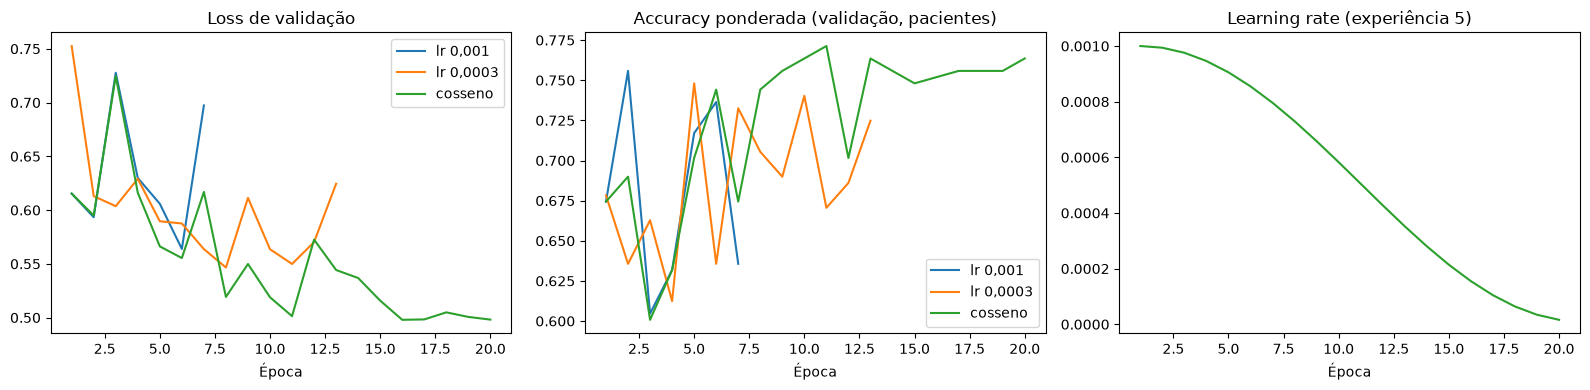

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for h, nome in [(hist_cnn3b, "lr 0,001"), (hist_cnn4, "lr 0,0003"), (hist_cnn5, "cosseno")]:
    axes[0].plot(h["epoch"], h["val_loss"], label=nome)
    axes[1].plot(h["epoch"], h["val_wacc"], label=nome)
axes[2].plot(hist_cnn5["epoch"], hist_cnn5["lr"], color="tab:green")
axes[0].set_title("Loss de validação")
axes[1].set_title("Accuracy ponderada (validação, pacientes)")
axes[2].set_title("Learning rate (experiência 5)")
for ax in axes: ax.set_xlabel("Época")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

**Resultados da experiência 5 (decaimento em cosseno, 20 épocas, class weights suavizados):**

- O treino estabilizou. Nas últimas cinco épocas, a loss de validação mantém-se entre 0,498 e 0,505, os valores mais baixos de todas as experiências, e o F1 das janelas sobe até cerca de 0,61, o melhor valor obtido.
- A accuracy ponderada por paciente deixou de oscilar: a partir da época 13 varia apenas entre 0,748 e 0,764, e o recall de Present fixa-se em 0,720 nas últimas sete épocas. Na experiência 4, a métrica variava entre 0,612 e 0,748.
- O melhor valor (0,771, época 11) resulta da escolha do máximo de uma série com alguma variação aleatória, pelo que é ligeiramente otimista. Como medida mais robusta, usa-se a média das últimas 5 épocas: 0,757.
- A partir daqui, o treino usa decaimento em cosseno durante 20 épocas, e as configurações são comparadas pela média da accuracy ponderada nas últimas 5 épocas.

### 5.6 Data augmentation

**Experiência 6: SpecAugment.** Para reduzir o overfitting, em cada época as janelas de treino são alteradas aleatoriamente, de forma a que o modelo nunca veja exatamente a mesma imagem duas vezes:
- **máscara no tempo:** uma faixa de até 20 instantes (~0,6 s) é substituída pelo valor médio do espectrograma, o que obriga o modelo a não depender de um único ciclo cardíaco;
- **máscara na frequência:** uma faixa de até 8 bandas mel é substituída da mesma forma, o que obriga o modelo a não depender de uma única banda de frequência.

As máscaras são pequenas, para não apagarem por completo a região dos sopros, concentrada nas frequências baixas. A augmentation é aplicada apenas no treino. A receita de treino é a da experiência 5 (decaimento em cosseno, 20 épocas, class weights suavizados), pelo que a única diferença é a augmentation.

In [78]:
class AugDataset(FeatureDataset):
    def __init__(self, X, y, idx, max_t=20, max_f=8):
        super().__init__(X, y, idx)
        self.max_t, self.max_f = max_t, max_f

    def __getitem__(self, i):
        j = self.idx[i]
        x = self.X[j].copy()                 # (1, 64, 157) — cópia, para não estragar o original
        valor = x.mean()

        # máscara no tempo
        t = np.random.randint(0, self.max_t + 1)
        t0 = np.random.randint(0, x.shape[2] - t + 1)
        x[:, :, t0 : t0 + t] = valor

        # máscara na frequência
        f = np.random.randint(0, self.max_f + 1)
        f0 = np.random.randint(0, x.shape[1] - f + 1)
        x[:, f0 : f0 + f, :] = valor

        return torch.from_numpy(x), int(self.y[j])

Exemplos da mesma janela com máscaras aleatórias.

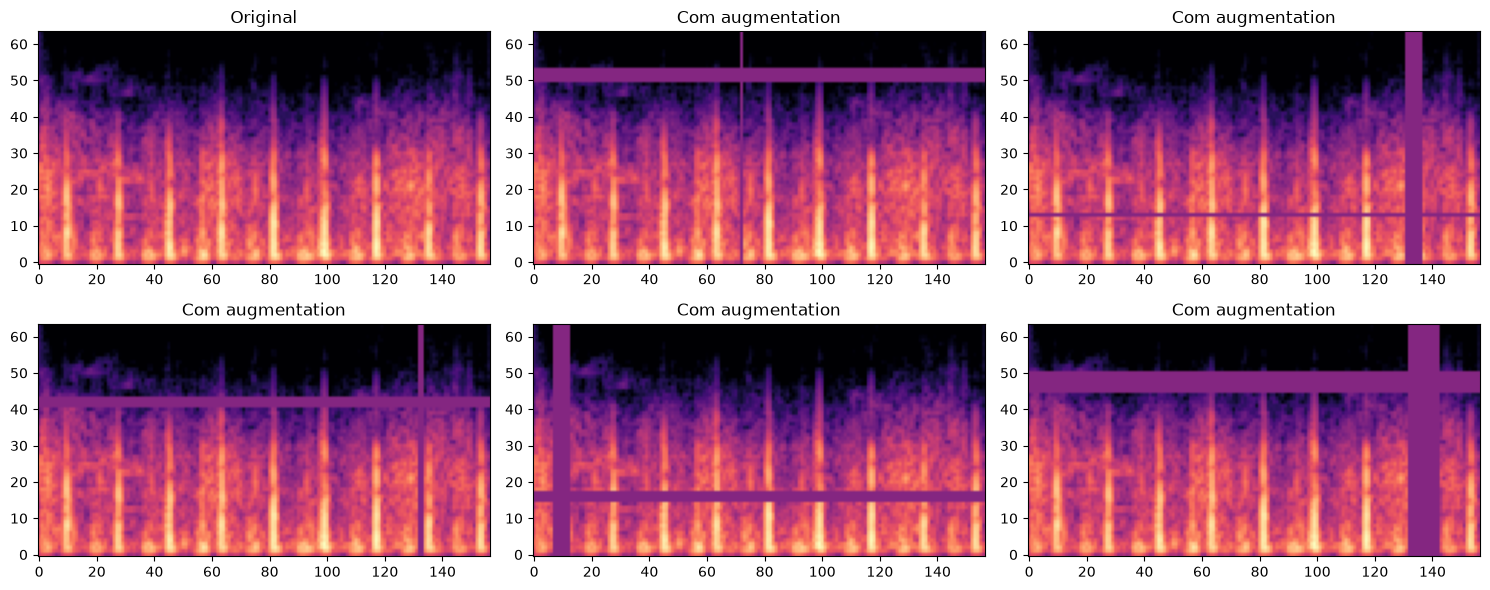

In [79]:
ds_aug = AugDataset(X_mel, y_all, train_idx)
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
axes[0, 0].imshow(X_mel[train_idx[0]][0], origin="lower", aspect="auto", cmap="magma")
axes[0, 0].set_title("Original")
for ax in axes.flat[1:]:
    x, _ = ds_aug[0]
    ax.imshow(x[0], origin="lower", aspect="auto", cmap="magma")
    ax.set_title("Com augmentation")
plt.tight_layout(); plt.show()

Treino da experiência 6 e comparação com a experiência 5.

In [80]:
train_loader_aug = DataLoader(AugDataset(X_mel, y_all, train_idx), batch_size=32, shuffle=True)

torch.manual_seed(SEED); np.random.seed(SEED)
cnn6 = CNN().to(device)
hist_cnn6 = fit(cnn6, train_loader_aug, val_loader, val_idx, loss_fn_sqrt,
                n_epochs=20, lr=1e-3, patience=None, cosine=True)

for nome, h in [("Exp. 5 (sem augmentation)", hist_cnn5), ("Exp. 6 (SpecAugment)", hist_cnn6)]:
    print(f"{nome}: média das últimas 5 épocas = {h['val_wacc'].tail(5).mean():.3f}")

Época  1 | lr 0.00100 | train loss 0.828 | val loss 0.640 | F1 janelas 0.462 | wacc pac. 0.659 | recall Present pac. 0.560 | 59s *
Época  2 | lr 0.00099 | train loss 0.741 | val loss 0.639 | F1 janelas 0.501 | wacc pac. 0.616 | recall Present pac. 0.400 | 57s
Época  3 | lr 0.00098 | train loss 0.703 | val loss 0.671 | F1 janelas 0.464 | wacc pac. 0.593 | recall Present pac. 0.400 | 57s
Época  4 | lr 0.00095 | train loss 0.689 | val loss 0.629 | F1 janelas 0.476 | wacc pac. 0.651 | recall Present pac. 0.520 | 57s
Época  5 | lr 0.00091 | train loss 0.670 | val loss 0.538 | F1 janelas 0.547 | wacc pac. 0.698 | recall Present pac. 0.640 | 57s *
Época  6 | lr 0.00086 | train loss 0.659 | val loss 0.598 | F1 janelas 0.540 | wacc pac. 0.674 | recall Present pac. 0.520 | 57s
Época  7 | lr 0.00080 | train loss 0.649 | val loss 0.577 | F1 janelas 0.535 | wacc pac. 0.655 | recall Present pac. 0.480 | 58s
Época  8 | lr 0.00073 | train loss 0.642 | val loss 0.536 | F1 janelas 0.557 | wacc pac. 0.72

**Resultados da experiência 6 (SpecAugment):**

| | Exp. 5 (sem augmentation) | Exp. 6 (SpecAugment) |
|---|---:|---:|
| Accuracy ponderada (média das últimas 5 épocas) | 0,757 | 0,753 |
| Loss de treino final | 0,526 | 0,587 |
| Loss de validação final | 0,498 | 0,513 |

- A augmentation não melhorou a accuracy ponderada: a diferença (0,753 vs 0,757) corresponde a um ponto em 258 e não é significativa.
- A loss de treino ficou mais alta (0,587 contra 0,526), como esperado, porque as janelas com partes apagadas são mais difíceis de classificar. A loss de validação não melhorou (0,513 contra 0,498).
- Em ambas as experiências, a loss de validação final é inferior à de treino, ou seja, esta CNN pequena não mostra sinais de overfitting. Isso explica porque é que a augmentation, que serve para o combater, não trouxe ganhos.
- Se o fator limitante não é o overfitting, pode ser a capacidade do modelo. A experiência seguinte testa uma rede maior, mantendo a augmentation para a proteger de decorar os dados de treino.

**Experiência 7: CNN maior com SpecAugment.** O número de filtros de cada bloco duplica, de 16/32/64 para 32/64/128, o que dá cerca de 94 mil parâmetros (quatro vezes mais). A receita de treino e a augmentation são as da experiência 6.

A classe CNN passa a receber o número de filtros como argumento; por defeito continua a usar 16/32/64.

In [81]:
class CNN(nn.Module):
    def __init__(self, n_classes=3, filtros=(16, 32, 64)):                      # NOVO
        super().__init__()

        def bloco(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )

        f1, f2, f3 = filtros                                                     # NOVO
        self.features = nn.Sequential(bloco(1, f1), bloco(f1, f2), bloco(f2, f3))  # NOVO
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(f3, n_classes),                                            # NOVO
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x)

Treino da experiência 7.

In [82]:
torch.manual_seed(SEED); np.random.seed(SEED)
cnn7 = CNN(filtros=(32, 64, 128)).to(device)
print(f"Parâmetros: {sum(p.numel() for p in cnn7.parameters()):,}")
hist_cnn7 = fit(cnn7, train_loader_aug, val_loader, val_idx, loss_fn_sqrt,
                n_epochs=20, lr=1e-3, patience=None, cosine=True)
print(f"Exp. 7: média das últimas 5 épocas = {hist_cnn7['val_wacc'].tail(5).mean():.3f}")

Parâmetros: 93,507
Época  1 | lr 0.00100 | train loss 0.792 | val loss 0.677 | F1 janelas 0.448 | wacc pac. 0.698 | recall Present pac. 0.720 | 109s *
Época  2 | lr 0.00099 | train loss 0.713 | val loss 0.573 | F1 janelas 0.527 | wacc pac. 0.725 | recall Present pac. 0.640 | 109s *
Época  3 | lr 0.00098 | train loss 0.681 | val loss 0.578 | F1 janelas 0.531 | wacc pac. 0.640 | recall Present pac. 0.480 | 109s
Época  4 | lr 0.00095 | train loss 0.662 | val loss 0.576 | F1 janelas 0.508 | wacc pac. 0.647 | recall Present pac. 0.520 | 110s
Época  5 | lr 0.00091 | train loss 0.643 | val loss 0.558 | F1 janelas 0.521 | wacc pac. 0.702 | recall Present pac. 0.640 | 111s
Época  6 | lr 0.00086 | train loss 0.644 | val loss 0.577 | F1 janelas 0.530 | wacc pac. 0.678 | recall Present pac. 0.560 | 109s
Época  7 | lr 0.00080 | train loss 0.627 | val loss 0.682 | F1 janelas 0.511 | wacc pac. 0.605 | recall Present pac. 0.400 | 110s
Época  8 | lr 0.00073 | train loss 0.610 | val loss 0.573 | F1 jane

**Resultados da experiência 7 (CNN 32/64/128 com SpecAugment):**

| Experiência | Configuração | Parâmetros | Tempo por época | Accuracy ponderada (média últimas 5) |
|---|---|---:|---:|---:|
| 5 | CNN 16/32/64 | 24 mil | ~57 s | 0,757 |
| 6 | CNN 16/32/64 + SpecAugment | 24 mil | ~60 s | 0,753 |
| 7 | CNN 32/64/128 + SpecAugment | 94 mil | ~112 s | 0,767 |

- A rede maior tem o valor mais alto (0,767), mas a diferença para a experiência 5 (0,010, cerca de meio paciente Present) é inferior à variação entre épocas. As três configurações são equivalentes.
- A rede maior demora o dobro do tempo a treinar, sem um ganho mensurável.

### 5.7 Conclusões sobre a CNN

Ao longo das experiências foram testados o peso das classes na loss, o learning rate e o seu decaimento, a data augmentation e a capacidade da rede. O que mais contribuiu foi a forma de treinar e de avaliar: os pesos suavizados, a avaliação por paciente e o decaimento em cosseno, que tornou o treino estável. A partir daí, o desempenho estabilizou num patamar de accuracy ponderada de cerca de 0,75–0,77 na validação, independentemente da augmentation e do tamanho da rede. Isto sugere que o limite do desempenho está nos próprios dados, e não no modelo:
- muitos sopros são fracos e difíceis de distinguir, mesmo por um ouvinte humano;
- o ruído de fundo pode confundir-se com um sopro;
- a classe Unknown é ambígua por natureza e só é reconhecida em parte (2 a 4 dos 10 pacientes de validação, consoante a experiência);
- com apenas 25 pacientes Present na validação, diferenças pequenas entre configurações não são mensuráveis.

Entre configurações equivalentes, escolhe-se a mais simples: a CNN da experiência 5 (16/32/64 filtros, class weights suavizados, Adam com decaimento em cosseno durante 20 épocas, sem augmentation) é o modelo CNN final, a avaliar no conjunto de teste no fim do trabalho.

## 6. Modelo 2: RNN (GRU)

### 6.1 Normalização dos MFCCs

Os 20 coeficientes MFCC têm escalas muito diferentes (o primeiro, relacionado com a energia total, tem valores muito maiores do que os restantes), o que prejudica o treino de redes recorrentes. Cada coeficiente é normalizado para média 0 e desvio-padrão 1. A média e o desvio-padrão são calculados apenas com as janelas de treino e depois aplicados a todos os conjuntos, para evitar data leakage.

In [83]:
mu = X_mfcc[train_idx].mean(axis=(0, 1))
sd = X_mfcc[train_idx].std(axis=(0, 1))
X_mfcc_n = ((X_mfcc - mu) / (sd + 1e-8)).astype(np.float32)

print("Antes: ", X_mfcc[train_idx].mean(axis=(0, 1))[:5].round(1))
print("Depois:", X_mfcc_n[train_idx].mean(axis=(0, 1))[:5].round(2), X_mfcc_n[train_idx].std(axis=(0, 1))[:5].round(2))

Antes:  [-89.6 155.1 -28.   -2.4   7.8]
Depois: [ 0. -0.  0.  0.  0.] [1. 1. 1. 1. 1.]


### 6.2 Arquitetura

A RNN recebe a sequência de 157 vetores de MFCCs normalizados (um a cada ~32 ms) e é composta por:
- **GRU com 2 camadas e estado oculto de dimensão 64:** processa a sequência passo a passo, atualizando a sua memória (o estado oculto) com cada novo instante. A segunda camada recebe a sequência de estados da primeira, o que permite modelar padrões temporais mais complexos. Entre as camadas é aplicado dropout (0,3).
- **Estado oculto final:** depois do último passo, o estado oculto da última camada resume a janela inteira.
- **Dropout (0,3) e camada linear**, que produz os 3 logits.

Usa-se uma GRU em vez de uma RNN simples por ser capaz de manter informação durante muitos passos (graças às suas portas), o que é necessário para relacionar eventos de ciclos cardíacos diferentes. A GRU tem menos parâmetros do que uma LSTM, uma vantagem com um dataset pequeno.

In [84]:
class RNN(nn.Module):
    def __init__(self, n_features=N_MFCC, hidden=64, n_layers=2, n_classes=3):
        super().__init__()
        self.gru = nn.GRU(input_size=n_features, hidden_size=hidden, num_layers=n_layers,
                          batch_first=True, dropout=0.3 if n_layers > 1 else 0)    # ← linha mudada
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(hidden, n_classes),
        )

    def forward(self, x):                 # x: (B, 157, 20)
        _, h = self.gru(x)                # h: (n_layers, B, hidden)
        return self.classifier(h[-1])     # estado final da última camada → (B, 3)

Verificação da forma da saída e do número de parâmetros.

In [85]:
rnn = RNN().to(device)
xb, yb = next(iter(DataLoader(FeatureDataset(X_mfcc_n, y_all, train_idx), batch_size=32, shuffle=True)))
print(rnn(xb.to(device)).shape)
print(f"Parâmetros: {sum(p.numel() for p in rnn.parameters()):,}")

torch.Size([32, 3])
Parâmetros: 41,667


### 6.3 Treino

**Experiência R1:** a RNN é treinada com a receita final da CNN (class weights suavizados, Adam com learning rate inicial de 0,001 e decaimento em cosseno durante 20 épocas), para que a comparação entre os dois modelos se deva à arquitetura e à representação de input, e não ao procedimento de treino.

In [86]:
train_loader_rnn = DataLoader(FeatureDataset(X_mfcc_n, y_all, train_idx), batch_size=32, shuffle=True)
val_loader_rnn = DataLoader(FeatureDataset(X_mfcc_n, y_all, val_idx), batch_size=64, shuffle=False)

torch.manual_seed(SEED)
rnn1 = RNN().to(device)
hist_rnn1 = fit(rnn1, train_loader_rnn, val_loader_rnn, val_idx, loss_fn_sqrt,
                n_epochs=20, lr=1e-3, patience=None, cosine=True)
print(f"RNN R1: média das últimas 5 épocas = {hist_rnn1['val_wacc'].tail(5).mean():.3f}")

Época  1 | lr 0.00100 | train loss 0.828 | val loss 0.614 | F1 janelas 0.499 | wacc pac. 0.651 | recall Present pac. 0.520 | 28s *
Época  2 | lr 0.00099 | train loss 0.617 | val loss 0.546 | F1 janelas 0.560 | wacc pac. 0.725 | recall Present pac. 0.680 | 27s *
Época  3 | lr 0.00098 | train loss 0.554 | val loss 0.614 | F1 janelas 0.558 | wacc pac. 0.721 | recall Present pac. 0.840 | 27s
Época  4 | lr 0.00095 | train loss 0.506 | val loss 0.574 | F1 janelas 0.579 | wacc pac. 0.748 | recall Present pac. 0.720 | 27s *
Época  5 | lr 0.00091 | train loss 0.463 | val loss 0.564 | F1 janelas 0.601 | wacc pac. 0.736 | recall Present pac. 0.720 | 27s
Época  6 | lr 0.00086 | train loss 0.430 | val loss 0.582 | F1 janelas 0.602 | wacc pac. 0.717 | recall Present pac. 0.680 | 27s
Época  7 | lr 0.00080 | train loss 0.398 | val loss 0.562 | F1 janelas 0.607 | wacc pac. 0.756 | recall Present pac. 0.760 | 27s *
Época  8 | lr 0.00073 | train loss 0.360 | val loss 0.622 | F1 janelas 0.602 | wacc pac. 

**Resultados da experiência R1 (RNN com a receita da CNN):**

- A RNN treina duas vezes mais depressa do que a CNN (~27 s por época, contra ~57 s), porque os MFCCs são uma representação mais compacta do que o espectrograma mel.
- Apresenta um overfitting forte na loss: a de treino desce até 0,145, enquanto a de validação atinge o mínimo na época 2 (0,546) e depois sobe até 0,883. A diferença final entre as duas (0,74) contrasta com a CNN, em que a loss de validação final ficou abaixo da de treino. Ao contrário da CNN, cujos filtros locais e partilhados impõem uma restrição forte, a GRU consegue memorizar as sequências de treino.
- Apesar disso, a accuracy ponderada mantém-se alta e estável (entre 0,75 e 0,78 a partir da época 10): o aumento da loss de validação reflete sobretudo previsões cada vez mais confiantes, incluindo nos erros, e não mudanças na classe prevista.
- Accuracy ponderada (média das últimas 5 épocas): 0,773, ligeiramente acima da CNN (0,757), uma diferença de cerca de um paciente Present.

**Experiência R2: augmentation dos MFCCs.** Para combater o overfitting, aplica-se aos MFCCs de treino o equivalente ao SpecAugment: em cada época, uma faixa de até 20 instantes consecutivos (~0,6 s) e até 3 dos 20 coeficientes são substituídos por 0 (a média, após a normalização). A receita de treino é a mesma da experiência R1.

In [87]:
class AugMFCCDataset(FeatureDataset):
    def __init__(self, X, y, idx, max_t=20, max_c=3):
        super().__init__(X, y, idx)
        self.max_t, self.max_c = max_t, max_c

    def __getitem__(self, i):
        j = self.idx[i]
        x = self.X[j].copy()                      # (157, 20)

        t = np.random.randint(0, self.max_t + 1)
        t0 = np.random.randint(0, x.shape[0] - t + 1)
        x[t0 : t0 + t, :] = 0                     # máscara no tempo

        c = np.random.randint(0, self.max_c + 1)
        c0 = np.random.randint(0, x.shape[1] - c + 1)
        x[:, c0 : c0 + c] = 0                     # máscara nos coeficientes

        return torch.from_numpy(x), int(self.y[j])

train_loader_rnn_aug = DataLoader(AugMFCCDataset(X_mfcc_n, y_all, train_idx), batch_size=32, shuffle=True)

torch.manual_seed(SEED); np.random.seed(SEED)
rnn2 = RNN().to(device)
hist_rnn2 = fit(rnn2, train_loader_rnn_aug, val_loader_rnn, val_idx, loss_fn_sqrt,
                n_epochs=20, lr=1e-3, patience=None, cosine=True)
print(f"RNN R2: média das últimas 5 épocas = {hist_rnn2['val_wacc'].tail(5).mean():.3f}")

Época  1 | lr 0.00100 | train loss 0.849 | val loss 0.612 | F1 janelas 0.534 | wacc pac. 0.690 | recall Present pac. 0.600 | 27s *
Época  2 | lr 0.00099 | train loss 0.649 | val loss 0.554 | F1 janelas 0.552 | wacc pac. 0.713 | recall Present pac. 0.720 | 27s *
Época  3 | lr 0.00098 | train loss 0.590 | val loss 0.595 | F1 janelas 0.563 | wacc pac. 0.709 | recall Present pac. 0.800 | 27s
Época  4 | lr 0.00095 | train loss 0.548 | val loss 0.545 | F1 janelas 0.586 | wacc pac. 0.725 | recall Present pac. 0.720 | 27s *
Época  5 | lr 0.00091 | train loss 0.521 | val loss 0.549 | F1 janelas 0.599 | wacc pac. 0.767 | recall Present pac. 0.800 | 27s *
Época  6 | lr 0.00086 | train loss 0.491 | val loss 0.567 | F1 janelas 0.608 | wacc pac. 0.721 | recall Present pac. 0.680 | 27s
Época  7 | lr 0.00080 | train loss 0.474 | val loss 0.545 | F1 janelas 0.600 | wacc pac. 0.748 | recall Present pac. 0.760 | 27s
Época  8 | lr 0.00073 | train loss 0.451 | val loss 0.547 | F1 janelas 0.617 | wacc pac. 

**Resultados da experiência R2 (augmentation dos MFCCs):**

| | R1 (sem augmentation) | R2 (com augmentation) |
|---|---:|---:|
| Loss de treino final | 0,145 | 0,315 |
| Loss de validação final | 0,883 | 0,651 |
| Diferença validação − treino | 0,74 | 0,34 |
| Accuracy ponderada (média últimas 5 épocas) | 0,773 | 0,774 |

- A augmentation reduziu o overfitting para menos de metade: a diferença entre a loss de validação e a de treino desceu de 0,74 para 0,34, e a loss de validação final de 0,883 para 0,651.
- A accuracy ponderada, no entanto, ficou igual (0,774 contra 0,773). O overfitting que se via na loss não estava a prejudicar a classe prevista para cada paciente.
- O overfitting continua presente (a loss de validação volta a subir a partir da época 8), o que indica que a RNN ainda tem capacidade a mais para o volume de dados disponível.

**Experiência R3: RNN mais pequena.** Como a RNN continua com um overfitting elevado, reduz-se a sua capacidade: uma única camada GRU com estado oculto de dimensão 32, em vez de duas camadas de dimensão 64 (cerca de 8 vezes menos parâmetros). Mantém-se a augmentation e a receita de treino da experiência R2.

In [88]:
torch.manual_seed(SEED); np.random.seed(SEED)
rnn3 = RNN(hidden=32, n_layers=1).to(device)
print(f"Parâmetros: {sum(p.numel() for p in rnn3.parameters()):,}")
hist_rnn3 = fit(rnn3, train_loader_rnn_aug, val_loader_rnn, val_idx, loss_fn_sqrt,
                n_epochs=20, lr=1e-3, patience=None, cosine=True)
print(f"RNN R3: média das últimas 5 épocas = {hist_rnn3['val_wacc'].tail(5).mean():.3f}")

Parâmetros: 5,283
Época  1 | lr 0.00100 | train loss 0.920 | val loss 0.779 | F1 janelas 0.398 | wacc pac. 0.450 | recall Present pac. 0.120 | 11s *
Época  2 | lr 0.00099 | train loss 0.823 | val loss 0.686 | F1 janelas 0.510 | wacc pac. 0.647 | recall Present pac. 0.520 | 11s *
Época  3 | lr 0.00098 | train loss 0.732 | val loss 0.630 | F1 janelas 0.528 | wacc pac. 0.671 | recall Present pac. 0.600 | 11s *
Época  4 | lr 0.00095 | train loss 0.660 | val loss 0.594 | F1 janelas 0.555 | wacc pac. 0.713 | recall Present pac. 0.720 | 11s *
Época  5 | lr 0.00091 | train loss 0.612 | val loss 0.560 | F1 janelas 0.566 | wacc pac. 0.733 | recall Present pac. 0.720 | 11s *
Época  6 | lr 0.00086 | train loss 0.579 | val loss 0.567 | F1 janelas 0.576 | wacc pac. 0.705 | recall Present pac. 0.720 | 11s
Época  7 | lr 0.00080 | train loss 0.558 | val loss 0.570 | F1 janelas 0.588 | wacc pac. 0.705 | recall Present pac. 0.680 | 11s
Época  8 | lr 0.00073 | train loss 0.547 | val loss 0.560 | F1 janela

**Resultados da experiência R3 (RNN mais pequena: 1 camada GRU de dimensão 32, com augmentation):**

| Experiência | Configuração | Parâmetros | Tempo por época | Val − train loss | Accuracy ponderada (média últimas 5) |
|---|---|---:|---:|---:|---:|
| R1 | GRU 2×64 | 41 667 | 27 s | 0,74 | 0,773 |
| R2 | GRU 2×64 + augmentation | 41 667 | 27 s | 0,34 | 0,774 |
| R3 | GRU 1×32 + augmentation | 5 283 | 11 s | 0,12 | 0,756 |

- A RNN mais pequena tem 8 vezes menos parâmetros, treina 2,5 vezes mais depressa e quase elimina o overfitting: a diferença entre a loss de validação e a de treino desce para 0,12, e a loss de validação deixa de subir.
- A accuracy ponderada fica ligeiramente abaixo da R1 e da R2 (0,756 contra 0,774). A diferença corresponde a cerca de um paciente Present e está dentro da variação observada entre épocas.
- O treino é regular: a métrica sobe de forma progressiva e estabiliza em 0,764 nas últimas três épocas, com o recall de Present em 0,800.

### 6.4 Conclusões sobre a RNN

A RNN original (2 camadas de dimensão 64) memoriza as sequências de treino: a loss de validação sobe enquanto a de treino desce. A data augmentation e a redução da capacidade da rede diminuíram progressivamente esse overfitting (a diferença entre a loss de validação e a de treino passou de 0,74 para 0,12), mas sem ganho na accuracy ponderada, que se manteve entre 0,76 e 0,77.

As três configurações são consideradas equivalentes, e escolhe-se a mais simples e com menos overfitting: a RNN final é a da experiência R3 (1 camada GRU de dimensão 32, augmentation dos MFCCs, class weights suavizados, Adam com decaimento em cosseno durante 20 épocas). Esta escolha tem um custo possível: a R1 e a R2 tiveram uma média de validação ligeiramente mais alta.

O desempenho da RNN na validação (~0,76–0,77) é semelhante ao da CNN (~0,75–0,77). Dois modelos com arquiteturas e representações do som muito diferentes atingem o mesmo patamar, o que reforça a conclusão de que o limite está sobretudo nos dados (sopros fracos, ruído de fundo e a ambiguidade da classe Unknown) e não na escolha do modelo.

## 7. Combinação dos modelos e avaliação final

### 7.1 Ensemble CNN + RNN

A CNN e a RNN representam o som de formas diferentes (imagem tempo-frequência vs sequência temporal), pelo que podem errar em pacientes diferentes. Testa-se um ensemble simples: para cada janela, as probabilidades das duas redes são somadas e divididas por dois, e a agregação por paciente segue a regra hierárquica habitual. O ensemble é avaliado primeiro na validação, e só é considerado se melhorar claramente em relação a cada modelo isolado.

In [89]:
from sklearn.metrics import roc_auc_score

val_loader_cnn = DataLoader(FeatureDataset(X_mel, y_all, val_idx), batch_size=64, shuffle=False)
val_loader_rnn = DataLoader(FeatureDataset(X_mfcc_n, y_all, val_idx), batch_size=64, shuffle=False)

p_cnn = predict_probs(cnn5, val_loader_cnn)
p_rnn = predict_probs(rnn3, val_loader_rnn)
p_ens = (p_cnn + p_rnn) / 2

def unknown_score(probs, idx):
    w = windows.loc[idx, ["patient_id"]].copy()
    w["p_unk"] = probs[:, 2]                      # probabilidade de Unknown de cada janela
    s = w.groupby("patient_id")["p_unk"].mean()   # média por paciente
    y = (labels.set_index("Patient ID").loc[s.index, "Murmur"] == "Unknown").astype(int)
    return y, s

for nome, p in [("CNN", p_cnn), ("RNN", p_rnn)]:
    y, s = unknown_score(p, val_idx)
    print(nome, "| AUC Unknown vs resto:", round(roc_auc_score(y, s), 3))
    print(s.groupby(y).describe()[["mean", "50%", "max"]].round(3))

CNN | AUC Unknown vs resto: 0.845
         mean    50%    max
Murmur                     
0       0.097  0.072  0.361
1       0.246  0.205  0.474
RNN | AUC Unknown vs resto: 0.715
         mean    50%    max
Murmur                     
0       0.114  0.089  0.587
1       0.236  0.171  0.554


**Resultados do ensemble (validação): POR ATUALIZAR**

Na última execução, o ciclo que imprimia os relatórios da CNN, da RNN e do ensemble foi substituído, na célula acima, pelo diagnóstico da AUC, por isso o resultado do ensemble não está no output. Para o recuperar, o fim da célula acima deve voltar a ser:

```python
for nome, p in [("CNN (exp. 5)", p_cnn), ("RNN (R3)", p_rnn), ("Ensemble", p_ens)]:
    y_true, y_pred = patient_predict(p, val_idx)
    patient_report(y_true, y_pred, f"{nome} — validação")
```

Valores já conhecidos (WAmurmur na validação, melhor época): CNN (exp. 5) 0,771 e RNN (R3) 0,764. Falta o valor do ensemble. O critério definido à partida mantém-se: o ensemble só é adotado se melhorar a WAmurmur de validação em pelo menos 0,03 em relação ao melhor modelo isolado. Depois de correr a célula, esta nota deve ser substituída pela tabela de resultados e pela decisão.

### 7.2 Classe Unknown: limiar de decisão

Nas experiências anteriores, a classe Unknown quase nunca é prevista. Primeiro verifica-se se os modelos têm informação sobre esta classe: para cada paciente calcula-se a média da probabilidade de Unknown das suas janelas e mede-se, com a AUC, se esse valor separa os pacientes Unknown dos restantes (0,5 corresponde ao acaso).

Se houver sinal, o problema está na regra de decisão: a regra hierárquica só atribui Unknown quando esta é a classe mais provável de uma gravação, o que quase nunca acontece. Testa-se por isso uma regra com limiar:
1. se alguma gravação for prevista como Present, o paciente é Present (como antes);
2. caso contrário, se a probabilidade média de Unknown do paciente ultrapassar um limiar, o paciente é Unknown;
3. caso contrário, é Absent.

O limiar é escolhido na validação, de forma a maximizar a WAmurmur. Tal como no ensemble, a nova regra só é adotada se melhorar a WAmurmur de validação em pelo menos 0,03.

In [90]:
for nome, p in [("CNN", p_cnn), ("RNN", p_rnn)]:
    y, s = unknown_score(p, val_idx)
    print(nome, "| AUC Unknown vs resto:", round(roc_auc_score(y, s), 3))
    print(s.groupby(y).describe()[["mean", "50%", "max"]].round(3))

CNN | AUC Unknown vs resto: 0.845
         mean    50%    max
Murmur                     
0       0.097  0.072  0.361
1       0.246  0.205  0.474
RNN | AUC Unknown vs resto: 0.715
         mean    50%    max
Murmur                     
0       0.114  0.089  0.587
1       0.236  0.171  0.554


Regra com limiar e escolha do limiar na validação.

In [91]:
def patient_predict_thr(probs, idx, t):
    y_true, y_pred = patient_predict(probs, idx)              # regra hierárquica habitual
    w = windows.loc[idx, ["patient_id"]].copy()
    w["p_unk"] = probs[:, 2]
    p_unk = w.groupby("patient_id")["p_unk"].mean().loc[y_pred.index]
    y_new = y_pred.copy()
    y_new[(y_pred != "Present") & (p_unk > t)] = "Unknown"    # Present mantém a prioridade
    return y_true, y_new

limiares = np.arange(0.08, 0.32, 0.02)
limiar_final = {}
for nome, p in [("CNN (exp. 5)", p_cnn), ("RNN (R3)", p_rnn)]:
    base = weighted_accuracy(*patient_predict(p, val_idx))
    res = [(t, weighted_accuracy(*patient_predict_thr(p, val_idx, t))) for t in limiares]
    t_best, wa_best = max(res, key=lambda r: r[1])
    adota = wa_best - base >= 0.03
    limiar_final[nome] = t_best if adota else None
    print(f"{nome}: sem limiar {base:.3f} | melhor limiar {t_best:.2f} → {wa_best:.3f} | adotado: {adota}")
    print("   ", " ".join(f"{t:.2f}:{wa:.3f}" for t, wa in res))

CNN (exp. 5): sem limiar 0.771 | melhor limiar 0.30 → 0.775 | adotado: False
    0.08:0.678 0.10:0.705 0.12:0.740 0.14:0.736 0.16:0.744 0.18:0.752 0.20:0.764 0.22:0.767 0.24:0.771 0.26:0.771 0.28:0.767 0.30:0.775
RNN (R3): sem limiar 0.764 | melhor limiar 0.24 → 0.771 | adotado: False
    0.08:0.643 0.10:0.690 0.12:0.729 0.14:0.733 0.16:0.748 0.18:0.760 0.20:0.756 0.22:0.760 0.24:0.771 0.26:0.764 0.28:0.764 0.30:0.764


**Resultados (validação):**

| Modelo | AUC Unknown vs resto | Prob. média de Unknown (pacientes Unknown / restantes) | WAmurmur sem limiar | Melhor limiar | WAmurmur com limiar | Adotado |
|---|---:|---:|---:|---:|---:|---|
| CNN (exp. 5) | 0,845 | 0,246 / 0,097 | 0,771 | 0,30 | 0,775 | Não |
| RNN (R3) | 0,715 | 0,236 / 0,114 | 0,764 | 0,24 | 0,771 | Não |

- Os modelos têm informação sobre a classe Unknown: a probabilidade média de Unknown é mais alta nos pacientes Unknown, e separa-os dos restantes bastante melhor do que o acaso, sobretudo na CNN (AUC de 0,845).
- Mesmo assim, o limiar quase não melhora a WAmurmur (+0,004 na CNN e +0,007 na RNN), muito abaixo do critério de 0,03, pelo que não é adotado. Na validação há 10 pacientes Unknown para 103 Absent: qualquer limiar que recupere alguns Unknown desvia também vários Absent, e os 3 pontos ganhos por cada Unknown são anulados pelos pontos perdidos nos Absent. Com limiares baixos (0,08–0,12), a métrica desce de forma clara.
- Foram testadas três formas de melhorar a classe Unknown: pesos fortes na loss (experiência 2), pesos suavizados (experiência 3) e o limiar de decisão. Só os pesos suavizados trouxeram um ganho, e parcial. Com estes inputs, a classe não é suficientemente separável: a informação que a define (a qualidade da gravação) é em parte removida pela normalização do sinal e do espectrograma. Um detetor de qualidade com features próprias fica como trabalho futuro.

### 7.3 Avaliação final no conjunto de teste

Os modelos finais, escolhidos apenas com base na validação, são avaliados uma única vez no conjunto de teste (145 pacientes nunca usados para nenhuma decisão: 104 Absent, 29 Present e 12 Unknown):
- **CNN:** experiência 5 (16/32/64 filtros, espectrograma mel, class weights suavizados, decaimento em cosseno);
- **RNN:** experiência R3 (GRU 1×32, MFCCs normalizados, augmentation, class weights suavizados, decaimento em cosseno).

A avaliação é feita por paciente, com a regra hierárquica, e a métrica principal é a WAmurmur. Os resultados do teste não são usados para alterar nenhum modelo.

=== CNN (exp. 5) — TESTE — 145 pacientes ===
              precision    recall  f1-score   support

      Absent      0.882     0.933     0.907       104
     Present      0.889     0.828     0.857        29
     Unknown      0.375     0.250     0.300        12

    accuracy                          0.855       145
   macro avg      0.715     0.670     0.688       145
weighted avg      0.841     0.855     0.846       145

WAmurmur (accuracy ponderada): 0.793

=== RNN (R3) — TESTE — 145 pacientes ===
              precision    recall  f1-score   support

      Absent      0.881     0.856     0.868       104
     Present      0.800     0.828     0.814        29
     Unknown      0.286     0.333     0.308        12

    accuracy                          0.807       145
   macro avg      0.656     0.672     0.663       145
weighted avg      0.816     0.807     0.811       145

WAmurmur (accuracy ponderada): 0.775



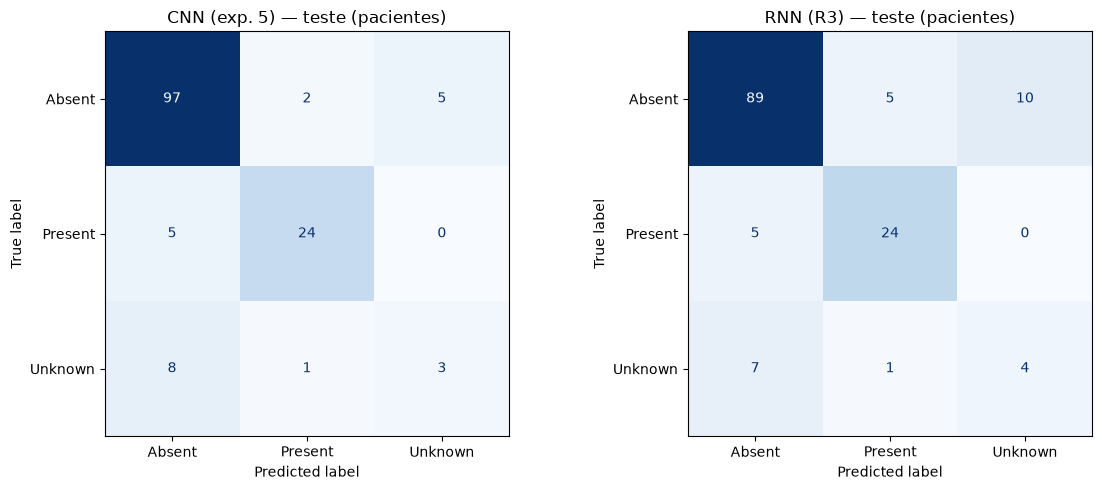

In [92]:
test_loader_cnn = DataLoader(FeatureDataset(X_mel, y_all, test_idx), batch_size=64, shuffle=False)
test_loader_rnn = DataLoader(FeatureDataset(X_mfcc_n, y_all, test_idx), batch_size=64, shuffle=False)

resultados_teste = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nome, modelo, loader) in zip(axes, [("CNN (exp. 5)", cnn5, test_loader_cnn),
                                              ("RNN (R3)", rnn3, test_loader_rnn)]):
    y_true, y_pred = patient_predict(predict_probs(modelo, loader), test_idx)
    patient_report(y_true, y_pred, f"{nome} — TESTE")
    resultados_teste[nome] = (y_true, y_pred)

    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=CLASSES),
                           display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{nome} — teste (pacientes)")

plt.tight_layout(); plt.show()

# Regra com limiar para o Unknown: só é avaliada se tiver sido adotada na validação (secção 7.2)
for nome, modelo, loader in [("CNN (exp. 5)", cnn5, test_loader_cnn), ("RNN (R3)", rnn3, test_loader_rnn)]:
    t = limiar_final[nome]
    if t is not None:
        y_true, y_pred = patient_predict_thr(predict_probs(modelo, loader), test_idx, t)
        patient_report(y_true, y_pred, f"{nome} com limiar Unknown {t:.2f} — TESTE")
        print(confusion_matrix(y_true, y_pred, labels=CLASSES))

**Resultados no conjunto de teste (145 pacientes)**

**Métricas obrigatórias**

| Modelo | WAmurmur |
|---|---:|
| CNN (exp. 5) | **0,793** |
| RNN (R3) | 0,775 |

Matrizes de confusão por paciente (linhas: classe real; colunas: classe prevista), também representadas na figura acima:

| CNN (exp. 5) | Prev. Absent | Prev. Present | Prev. Unknown |
|---|---:|---:|---:|
| Real Absent | 97 | 2 | 5 |
| Real Present | 5 | 24 | 0 |
| Real Unknown | 8 | 1 | 3 |

| RNN (R3) | Prev. Absent | Prev. Present | Prev. Unknown |
|---|---:|---:|---:|
| Real Absent | 89 | 5 | 10 |
| Real Present | 5 | 24 | 0 |
| Real Unknown | 7 | 1 | 4 |

**Métricas adicionais**

| Modelo | Recall Present | Recall Absent | Recall Unknown | Precisão Present | F1 macro |
|---|---:|---:|---:|---:|---:|
| CNN (exp. 5) | 0,828 | 0,933 | 0,250 | 0,889 | 0,688 |
| RNN (R3) | 0,828 | 0,856 | 0,333 | 0,800 | 0,663 |

**Análise:**
- Os dois modelos detetam exatamente o mesmo número de sopros: 24 dos 29 pacientes Present. Os 5 que falham são, em ambos, classificados como Absent.
- A diferença está nos pacientes Absent: a CNN acerta 97 dos 104 e a RNN 89. A RNN produz mais falsos alarmes, sobretudo para Unknown (10 pacientes Absent, contra 5 na CNN). Em troca, acerta mais um paciente Unknown (4 contra 3, em 12).
- No total, a CNN obtém 226 pontos em 285 e a RNN 221: uma diferença de 5 pontos, o equivalente a um paciente Present.
- Os resultados do teste são coerentes com os da validação (CNN 0,757 e RNN 0,756 na média das últimas épocas): os dois modelos têm desempenhos muito próximos, e os valores do teste até são ligeiramente superiores.
- A classe Unknown continua a ser a mais difícil: apenas 3 e 4 dos 12 pacientes são reconhecidos, e a maioria é classificada como Absent.

In [93]:
def bootstrap_ci(y_true, y_pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    vals = [weighted_accuracy(y_true[i], y_pred[i])
            for i in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

for nome, (yt, yp) in resultados_teste.items():
    lo, hi = bootstrap_ci(yt, yp)
    print(f"{nome}: {weighted_accuracy(yt, yp):.3f}  (IC 95 %: {lo:.3f} – {hi:.3f})")

CNN (exp. 5): 0.793  (IC 95 %: 0.704 – 0.884)
RNN (R3): 0.775  (IC 95 %: 0.678 – 0.858)


Bootstrap emparelhado da diferença entre os dois modelos.

In [94]:
yt, yp_cnn = resultados_teste["CNN (exp. 5)"]
_, yp_rnn = resultados_teste["RNN (R3)"]
yt, yp_cnn, yp_rnn = np.asarray(yt), np.asarray(yp_cnn), np.asarray(yp_rnn)

rng = np.random.default_rng(SEED)
difs = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    difs.append(weighted_accuracy(yt[i], yp_rnn[i]) - weighted_accuracy(yt[i], yp_cnn[i]))
lo, hi = np.percentile(difs, [2.5, 97.5])
print(f"Diferença RNN − CNN: {np.mean(difs):.3f}  (IC 95 %: {lo:.3f} – {hi:.3f})")
print(f"Proporção de sorteios em que a RNN é melhor: {np.mean(np.array(difs) > 0):.2f}")

Diferença RNN − CNN: -0.017  (IC 95 %: -0.076 – 0.051)
Proporção de sorteios em que a RNN é melhor: 0.28


**Incerteza da WAmurmur (intervalos de confiança por bootstrap, 1000 reamostragens dos pacientes de teste):**

| Modelo | WAmurmur | IC 95 % |
|---|---:|---|
| CNN (exp. 5) | 0,793 | 0,704 – 0,884 |
| RNN (R3) | 0,775 | 0,678 – 0,858 |

Os intervalos de confiança são largos (cerca de ±0,09), reflexo do pequeno número de pacientes Present (29) e Unknown (12) no teste, e sobrepõem-se quase por completo. No bootstrap emparelhado, em que os dois modelos são avaliados nos mesmos pacientes reamostrados, a diferença RNN − CNN é de −0,017 (IC 95 %: −0,076 a 0,051), e a RNN é melhor em 28 % das reamostragens. Como o intervalo inclui o 0, a diferença não é estatisticamente significativa: a CNN teve o melhor resultado, mas os dois modelos não se distinguem com este conjunto de teste.

## 8. Resumo das experiências e conclusões

### 8.1 Resumo das experiências

Todos os valores são da WAmurmur por paciente no conjunto de validação (138 pacientes), com a regra hierárquica.

**CNN (espectrograma mel)**

| Exp. | O que muda | WAmurmur (validação) | Conclusão |
|---|---|---:|---|
| 1 | Baseline, sem compensar o desequilíbrio | 0,725 | Nunca prevê Unknown |
| 2 | Class weights inversos à frequência | 0,698 | Prevê Unknown em excesso e perde pacientes Absent |
| 3 | Class weights suavizados (raiz quadrada) | 0,748 | Melhor compromisso; adotado |
| 1b / 3b | Época escolhida pela WAmurmur, com early stopping | 0,752 / 0,756 (melhor época) | Treino instável: a métrica salta muito entre épocas |
| 4 | Learning rate 0,0003 | 0,748 (melhor época) | Continua instável |
| 5 | Decaimento em cosseno, 20 épocas | 0,757 (média das últimas 5) | Treino estável; CNN final |
| 6 | + SpecAugment | 0,753 (média das últimas 5) | Sem ganho: a CNN não tinha overfitting |
| 7 | 32/64/128 filtros + SpecAugment | 0,767 (média das últimas 5) | Ganho dentro do ruído, com o dobro do tempo |

**RNN (MFCCs)**

| Exp. | O que muda | WAmurmur (validação, média das últimas 5) | Conclusão |
|---|---|---:|---|
| R1 | GRU 2×64, receita da CNN | 0,773 | Overfitting forte na loss |
| R2 | + augmentation dos MFCCs | 0,774 | Overfitting para metade, mesma métrica |
| R3 | GRU 1×32 + augmentation | 0,756 | 8 vezes menos parâmetros, quase sem overfitting; RNN final |

**Outras tentativas:** ensemble CNN + RNN (secção 7.1) e limiar de decisão para a classe Unknown (secção 7.2, não adotado).

### 8.2 Resumo do trabalho

O objetivo foi classificar pacientes do dataset CirCor DigiScope quanto à presença de sopro cardíaco (Present, Absent ou Unknown), a partir de gravações de auscultação, com dois modelos de deep learning: uma CNN e uma RNN.

O trabalho seguiu quatro etapas:
1. **Análise exploratória:** forte desequilíbrio entre classes (74 % Absent), durações das gravações muito variáveis (5–65 s), e a observação de que o sopro se distingue do ruído pela sincronização com o ciclo cardíaco.
2. **Pré-processamento:** divisão por paciente, mantendo no mesmo conjunto os dois registos das crianças que participaram nas duas campanhas; filtro passa-banda (25–400 Hz); normalização; janelas de 5 s com sobreposição de 50 %; e uma label por gravação (as gravações sem sopro audível de pacientes Present passaram a Absent para o treino).
3. **Representações e modelos:** o mesmo som representado como imagem (espectrograma mel) para a CNN e como sequência temporal (MFCCs) para a RNN.
4. **Experiências sistemáticas**, alterando um fator de cada vez, avaliadas por paciente com a WAmurmur.

### 8.3 Principais conclusões

- **A avaliação tem de refletir o problema real.** A accuracy das janelas (86 %) escondia que uma classe inteira nunca era prevista, e o F1 macro favorecia a experiência 2, que a WAmurmur mostrou ser pior. Avaliar por paciente, com a métrica do problema, levou a decisões diferentes.
- **Pesos de classe fortes prejudicam.** Compensar o desequilíbrio com pesos inversamente proporcionais à frequência levou o modelo a prever Unknown em excesso e a perder pacientes Absent (WAmurmur de 0,698, contra 0,725 sem pesos). Os pesos suavizados foram o melhor compromisso (0,748).
- **A estabilidade do treino é essencial para comparações fiáveis.** Com learning rate fixo, a métrica saltava mais de 0,10 de uma época para a seguinte, e o valor da melhor época era pouco fiável. O decaimento em cosseno estabilizou o treino: nas últimas épocas, a métrica passou a variar menos de 0,02.
- **A regularização tem efeitos diferentes nos dois modelos.** A CNN pequena não mostrou overfitting, e nem a augmentation nem uma rede maior melhoraram o resultado. A RNN mostrou um overfitting forte na loss; a augmentation e a redução da rede (8 vezes menos parâmetros) quase o eliminaram, mas sem ganho na WAmurmur.
- **A classe Unknown só é reconhecida em parte.** Pesos fortes, pesos suavizados e um limiar de decisão foram testados; no teste, os modelos finais reconhecem 3 e 4 dos 12 pacientes Unknown.
- **CNN vs RNN.** No teste, a CNN obteve uma WAmurmur de 0,793 e a RNN de 0,775. Ambas detetaram 24 dos 29 pacientes com sopro; a CNN produziu menos falsos alarmes. A diferença não é estatisticamente significativa (bootstrap emparelhado: −0,017, IC 95 % de −0,076 a 0,051). A RNN tem 4,5 vezes menos parâmetros (5 mil contra 24 mil) e treina cerca de 5 vezes mais depressa.

### 8.4 Limitações

- **Tamanho dos conjuntos de avaliação:** com 25 a 29 pacientes Present e 10 a 12 Unknown na validação e no teste, as métricas têm uma incerteza elevada (cerca de ±0,09) e diferenças pequenas entre modelos não são mensuráveis.
- **A classe Unknown:** é ambígua por natureza (o próprio especialista não decidiu) e tem muito poucos exemplos; nenhum modelo a reconheceu de forma fiável.
- **Um único split e uma única semente:** os resultados dependem da divisão concreta dos pacientes e da inicialização aleatória.
- **Escolha dos modelos finais:** entre configurações com diferenças dentro do ruído escolheu-se a mais simples. Na RNN, as configurações maiores tiveram uma média de validação ligeiramente superior.
- **Sopros fracos e ruído:** muitos sopros são de grau I/VI, difíceis de distinguir mesmo por um ouvinte humano, e o ruído de fundo sobrepõe-se à banda de frequência dos sopros.
- **Pacientes com poucas gravações:** se o sopro estiver numa válvula que não foi gravada, nenhum modelo o pode detetar.

### 8.5 Trabalho futuro

- **Validação cruzada por paciente** (por exemplo, 5 folds) e várias sementes, para obter estimativas mais estáveis e comparações estatisticamente mais sólidas.
- **Um detetor de qualidade para a classe Unknown**, com features calculadas antes da normalização (nível do sinal, saturação, energia fora da banda útil, regularidade do ritmo), aplicado antes do classificador de sopros.
- **Usar a segmentação dos ficheiros .tsv** no treino, por exemplo para criar janelas alinhadas com os ciclos cardíacos ou features específicas da sístole e da diástole, explorando a sincronização com o ciclo identificada na análise exploratória.
- **Melhorias simples nos modelos atuais:** um limiar de decisão para a classe Present ajustado na validação, e uma RNN bidirecional ou com a média dos estados de todos os passos em vez do último estado.
- **Arquiteturas que combinem os dois tipos de informação**, como uma CRNN (camadas convolucionais seguidas de uma camada recorrente), ou modelos pré-treinados em áudio.